# Question 1 — Image Restoration and Enhancement Pipeline
**CLO-1, GA-4 · P3 · 20 Marks**

| | |
|---|---|
| **Name** | ____________________ |
| **Registration No.** | ____________________ |
| **Course** | Computer Vision Lab (AI441L) |
| **Tools** | Python 3, OpenCV, NumPy, Matplotlib, SciPy (+ ipywidgets for the bonus GUI) |

**Goal.** Build an OpenCV/NumPy *preprocessing module* for a computer-vision system that receives low-quality images (poor lighting, limited resolution). The module must improve visual quality while **preserving structural information** (edges, object boundaries).

### Contents
| Section | Task | Marks |
|---|---|---|
| 0 | Setup, central parameter table, helper module | — |
| **A** | A1 representation & grayscale · A2 quantization · A3 translation / rotation / scaling | 5 |
| **B** | B1 brightness & contrast · B2 noise + spatial filters · B3 Sobel & Laplacian | 6 |
| **C** | C1 2-D DFT & log spectrum · C2 low-/high-pass design · C3 spatial vs frequency | 5 |
| **D** | D1 MSE / PSNR (reference defined) · D2 comparison table + "numerically better ≠ visually better" | 4 |
| E | Integrated low-light / low-resolution restoration pipeline (ties everything together) | — |
| **Bonus** | Interactive GUI (ipywidgets) — every operation with live sliders and live metrics | bonus |
| F | Conclusions & viva notes | — |

### How to run (Google Colab)
1. `Runtime ▸ Run all`.
2. If `input_image.png` is not in the Colab working directory, the loading cell opens an **upload button** — choose the image. Any name is accepted; it is saved as `input_image.png`.
3. Every tunable value lives in **one dictionary `P`** (Section 0). To answer an examiner's "change parameter X" request, edit `P`, then re-run from that section (or use the GUI).

**Controlled-comparison rule used everywhere (Instruction 6):** in each experiment only the parameter under investigation changes; all other settings are held at the values in `P`, and every random process uses the fixed seed `SEED = 42`.

## 0. Setup
### 0.1 Imports and environment

In [ ]:
import os, sys, time, textwrap
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import ndimage, signal

IN_COLAB = 'google.colab' in sys.modules
plt.rcParams.update({
    'figure.dpi': 80, 'savefig.dpi': 80,
    'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'figure.titlesize': 13, 'figure.titleweight': 'bold',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
})
print(f"Python      : {sys.version.split()[0]}")
print(f"OpenCV      : {cv2.__version__}")
print(f"NumPy       : {np.__version__}")
print(f"SciPy       : {scipy.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"Running in Colab: {IN_COLAB}")

Python      : 3.13.15
OpenCV      : 4.14.0
NumPy       : 2.1.3
SciPy       : 1.16.3
Matplotlib  : 3.10.0
Running in Colab: True


### 0.2 Central parameter table `P`
All experiment settings are collected here so that they are **justified in one place** and can be changed in one place.

| Parameter | Value | Justification |
|---|---|---|
| `quant_levels` | 256, 32, 8, 4, 2 | 8, 5, 3, 2, 1 bits — spans "no visible change" → "binary"; ≥ 4 levels incl. the original 8-bit as required. |
| `tx, ty` | 100, 60 px | ≈ 14 % / 5 % of width / height — clearly visible but keeps most content in frame. |
| `rot_angle` | 30° | Not a multiple of 90°, so interpolation **and** border filling are both exercised. |
| `scale_factors` | 0.5, 2.0 | One down-sampling and one up-sampling case (they need different interpolators). |
| `lowres_factor` | 0.25 | Simulates a "limited resolution" sensor (184 × 327 px) for the interpolation study. |
| `brightness_betas` | −50, +30, +70 | Darken / mild / strong brighten; ±70 ≈ 27 % of the range — strong enough to show clipping. |
| `contrast_alphas` | 0.5, 1.5, 2.5 | Compression / moderate / strong stretch around the mean. |
| `gammas` | 0.5, 0.75, 1.5 | γ < 1 lifts shadows (low-light case), γ > 1 darkens. |
| `gauss_noise_sigma` | 20 | ≈ 8 % of the range — typical high-ISO sensor noise. |
| `sp_density` | 0.05 | 5 % impulse pixels — clearly visible, < 50 % so the median filter is well-defined. |
| `filter_ksize` | 3 | Same 3 × 3 support for **all** spatial filters → fair comparison. The kernel-size sweep in B2 shows k = 3 gives the highest PSNR for every filter on this finely textured collage. |
| `gauss_filter_sigma` | 0.8 | OpenCV's standard σ for a 3 × 3 kernel, $0.3((k-1)/2-1)+0.8$; keeps the ±2σ span inside the window. |
| `D0_lp` | 60 | LPF cut-off radius (frequency samples): removes fine texture/noise but keeps faces and numbers recognisable (sweep 20/60/120 in C2). |
| `D0_hp` | 30 | HPF cut-off: passes edges and texture, removes shading; gives a clean high-boost result. |
| `highboost_k` | 1.5 | Amount of high-pass detail added back for sharpening. |
| `equiv_sigma` | 4 px | Spatial Gaussian σ used for the spatial-vs-frequency equivalence test in C3. |

In [ ]:
SEED = 42                       # one seed for every random process -> reproducible results

P = {
    # ---------------- Part A ----------------
    'quant_levels'      : [256, 32, 8, 4, 2],
    'tx'                : 100,
    'ty'                : 60,
    'rot_angle'         : 30,           # degrees, counter-clockwise
    'rot_scale'         : 1.0,
    'scale_factors'     : [0.5, 2.0],
    'lowres_factor'     : 0.25,
    # ---------------- Part B ----------------
    'brightness_betas'  : [-50, 30, 70],
    'contrast_alphas'   : [0.5, 1.5, 2.5],
    'gammas'            : [0.5, 0.75, 1.5],
    'gauss_noise_sigma' : 20,
    'sp_density'        : 0.05,
    'filter_ksize'      : 3,
    'gauss_filter_sigma': 0.8,
    'ksize_sweep'       : [3, 5, 7, 9, 11],
    'sobel_ksize'       : 3,
    'lap_ksize'         : 1,            # ksize=1 -> classic 4-neighbour kernel [[0,1,0],[1,-4,1],[0,1,0]]
    'log_sigma'         : 2.0,          # Gaussian pre-smoothing for Laplacian-of-Gaussian
    # ---------------- Part C ----------------
    'D0_lp'             : 60,
    'D0_hp'             : 30,
    'D0_sweep'          : [20, 60, 120],
    'highboost_k'       : 1.5,
    'equiv_sigma'       : 4.0,
    # ---------------- Part E (integrated pipeline) ----------------
    'sim_exposure'      : 0.35,         # under-exposure gain
    'sim_gamma'         : 1.6,          # non-linear shadow compression
    'sim_downscale'     : 0.5,          # resolution loss
    'sim_noise_sigma'   : 4,            # sensor noise (grey levels, in the dark image)
    'target_mean'       : 0.40,         # auto-exposure target for tone restoration
    'unsharp_k'         : 0.5,
    'unsharp_sigma'     : 1.5,
}
for k, v in P.items():
    print(f"{k:20s}: {v}")

quant_levels        : [256, 32, 8, 4, 2]
tx                  : 100
ty                  : 60
rot_angle           : 30
rot_scale           : 1.0
scale_factors       : [0.5, 2.0]
lowres_factor       : 0.25
brightness_betas    : [-50, 30, 70]
contrast_alphas     : [0.5, 1.5, 2.5]
gammas              : [0.5, 0.75, 1.5]
gauss_noise_sigma   : 20
sp_density          : 0.05
filter_ksize        : 3
gauss_filter_sigma  : 0.8
ksize_sweep         : [3, 5, 7, 9, 11]
sobel_ksize         : 3
lap_ksize           : 1
log_sigma           : 2.0
D0_lp               : 60
D0_hp               : 30
D0_sweep            : [20, 60, 120]
highboost_k         : 1.5
equiv_sigma         : 4.0
sim_exposure        : 0.35
sim_gamma           : 1.6
sim_downscale       : 0.5
sim_noise_sigma     : 4
target_mean         : 0.4
unsharp_k           : 0.5
unsharp_sigma       : 1.5


### 0.3 Helper module (re-used by every part)
`mse`, `psnr` and `ssim` are implemented from their definitions (SSIM follows Wang *et al.*, 2004, with an 11 × 11 Gaussian window, σ = 1.5) and cross-checked against `cv2.PSNR`.

In [ ]:
def to_u8(x):
    # Round and clip any array to valid 8-bit range.
    return np.clip(np.round(x), 0, 255).astype(np.uint8)

def norm_u8(x):
    # Min-max normalise any (signed / float) response to 0..255 for display only.
    x = x.astype(np.float64)
    lo, hi = x.min(), x.max()
    if hi - lo < 1e-12:
        return np.zeros(x.shape, np.uint8)
    return to_u8(255 * (x - lo) / (hi - lo))

def mse(ref, img):
    # MSE = 1/(MN) * sum (ref - img)^2
    d = ref.astype(np.float64) - img.astype(np.float64)
    return float(np.mean(d ** 2))

def psnr(ref, img, max_val=255.0):
    # PSNR = 10 log10(MAX^2 / MSE)  [dB]
    m = mse(ref, img)
    return float('inf') if m == 0 else 10 * np.log10(max_val ** 2 / m)

def ssim(ref, img):
    # Structural similarity: luminance x contrast x structure, averaged over local Gaussian windows.
    a, b = ref.astype(np.float64), img.astype(np.float64)
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    blur = lambda z: cv2.GaussianBlur(z, (11, 11), 1.5)
    mu_a, mu_b = blur(a), blur(b)
    s_aa = blur(a * a) - mu_a ** 2
    s_bb = blur(b * b) - mu_b ** 2
    s_ab = blur(a * b) - mu_a * mu_b
    smap = ((2 * mu_a * mu_b + C1) * (2 * s_ab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (s_aa + s_bb + C2))
    return float(smap.mean())

def entropy(img):
    # Shannon entropy of the grey-level histogram (bits / pixel).
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    p = hist[hist > 0] / hist.sum()
    return float(-(p * np.log2(p)).sum())

def metric_str(ref, img):
    return f"PSNR {psnr(ref, img):.2f} dB | SSIM {ssim(ref, img):.3f}"

def show_grid(images, titles, cols=4, suptitle=None, cmap='gray', panel=(3.4, 5.4),
              axis=False, raw_range=True, cmaps=None):
    # Display a list of images. 8-bit grey images use vmin=0, vmax=255 so that
    # brightness changes are shown truthfully (no matplotlib auto-scaling).
    n = len(images)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(panel[0] * cols, panel[1] * rows), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        if i >= n:
            ax.axis('off'); continue
        im = images[i]
        cm = cmaps[i] if cmaps is not None else cmap
        if im.ndim == 3:
            ax.imshow(im)
        elif raw_range and im.dtype == np.uint8:
            ax.imshow(im, cmap=cm, vmin=0, vmax=255)
        else:
            ax.imshow(im, cmap=cm)
        ax.set_title(titles[i])
        if not axis:
            ax.axis('off')
        else:
            ax.set_xlabel('x (column) [px]'); ax.set_ylabel('y (row) [px]')
    if suptitle:
        fig.suptitle(suptitle)
    fig.tight_layout()
    plt.show()

print("Helpers ready.")

Helpers ready.


---
# Part A — Image Representation and Geometric Transformations (5 marks)
## A1. Load the image, inspect its representation, convert to grayscale (1 mark)

**Image source documentation (Instruction 5)**
* **Source:** user-supplied photo collage (`input_image.png`), a portrait-format football wallpaper. *(Original web source: ______ — fill in.)*
* **File format:** PNG (lossless), stored as 4 channels (RGBA). The alpha channel is checked below and discarded by `cv2.IMREAD_COLOR`, giving a 3-channel image.
* **Preprocessing before the experiments:** none except BGR → RGB re-ordering for display and BT.601 grayscale conversion. **No resizing** — native resolution is used everywhere.

In [ ]:
IMG_PATH = 'input_image.png'

def get_image_path(path):
    # Use the local file if present; on Colab, otherwise open an upload dialog.
    if os.path.exists(path):
        return path
    if IN_COLAB:
        from google.colab import files
        print(f"'{path}' not found - please upload the image (PNG/JPG).")
        uploaded = files.upload()
        name = next(iter(uploaded))
        if name != path:
            with open(path, 'wb') as f:
                f.write(uploaded[name])
        return path
    raise FileNotFoundError(f"Put the image next to this notebook as '{path}'.")

IMG_PATH = get_image_path(IMG_PATH)

raw     = cv2.imread(IMG_PATH, cv2.IMREAD_UNCHANGED)   # exactly what is stored in the file
img_bgr = cv2.imread(IMG_PATH, cv2.IMREAD_COLOR)       # OpenCV loads colour as B, G, R
assert img_bgr is not None, "Image could not be read."
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)     # Matplotlib expects R, G, B
H, W, C = img_bgr.shape

print("=== IMAGE REPRESENTATION ===")
print(f"File                : {IMG_PATH}  ({os.path.getsize(IMG_PATH)/1024:.1f} KiB on disk, PNG)")
n_stored = 1 if raw.ndim == 2 else raw.shape[2]
print(f"Channels stored     : {n_stored} " + ("(R,G,B + alpha)" if n_stored == 4 else ""))
if n_stored == 4:
    a = raw[..., 3]
    print(f"Alpha channel       : min {a.min()}, max {a.max()}, "
          f"{100*np.mean(a == 255):.1f} % fully opaque -> dropped by IMREAD_COLOR (no information lost)")
print(f"Array shape (H,W,C) : {img_bgr.shape}   -> height {H} px, width {W} px, {C} channels")
print(f"Total pixels        : {H*W:,}")
print(f"Data type           : {img_bgr.dtype}  ({img_bgr.itemsize*8} bits per channel, "
      f"{img_bgr.itemsize*8*C} bits per pixel)")
print(f"Theoretical range   : [{np.iinfo(img_bgr.dtype).min}, {np.iinfo(img_bgr.dtype).max}]")
print(f"Actual range        : [{img_rgb.min()}, {img_rgb.max()}]")
for i, ch in enumerate('RGB'):
    c = img_rgb[..., i]
    print(f"  {ch}: min {c.min():3d}  max {c.max():3d}  mean {c.mean():6.2f}  std {c.std():6.2f}")
print(f"Memory in RAM       : {img_bgr.nbytes/1024:.1f} KiB")
print(f"Colour space        : sRGB, 8-bit, stored in OpenCV BGR order")

'input_image.png' not found - please upload the image (PNG/JPG).


**Grayscale conversion.** OpenCV uses the ITU-R BT.601 luma weights:
$$Y = 0.299\,R + 0.587\,G + 0.114\,B$$
The weights follow the eye's sensitivity (most to green, least to blue). Below the formula is applied manually and compared with `cv2.cvtColor`, and contrasted with a naive equal-weight average.

In [ ]:
R, G, B = [img_rgb[..., i].astype(np.float64) for i in range(3)]
gray_manual = to_u8(0.299 * R + 0.587 * G + 0.114 * B)
gray        = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)          # <- REFERENCE image for the whole notebook
gray_avg    = to_u8((R + G + B) / 3.0)

print(f"Grayscale shape {gray.shape}, dtype {gray.dtype}, range [{gray.min()}, {gray.max()}], "
      f"mean {gray.mean():.2f}, std {gray.std():.2f}")
print(f"max |manual BT.601 - cv2| = {np.abs(gray_manual.astype(int) - gray.astype(int)).max()} grey level "
      f"(fixed-point rounding inside OpenCV)")
print(f"Memory: colour {img_bgr.nbytes/1024:.0f} KiB -> grey {gray.nbytes/1024:.0f} KiB "
      f"({img_bgr.nbytes/gray.nbytes:.0f}x smaller)")
n_colours = len(np.unique(img_rgb.reshape(-1, 3), axis=0))
print(f"Distinct colours: {n_colours:,}  ->  distinct grey levels: {len(np.unique(gray))}")
print(f"Mean |BT.601 - equal average| = {np.abs(gray.astype(int) - gray_avg.astype(int)).mean():.2f} grey levels")

show_grid([img_rgb, img_rgb[..., 0], img_rgb[..., 1], img_rgb[..., 2], gray, gray_avg],
          [f"Original RGB {W}x{H}x3", "R channel", "G channel", "B channel",
           "Grayscale BT.601 (cv2)", "Equal-weight average (R+G+B)/3"],
          cols=6, panel=(2.9, 5.0), suptitle="A1 - Colour channels and grayscale conversion")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
for i, (ch, col) in enumerate(zip('RGB', ['tab:red', 'tab:green', 'tab:blue'])):
    ax[0].plot(np.bincount(img_rgb[..., i].ravel(), minlength=256), color=col, label=ch, lw=1)
ax[0].set_title('Histogram of RGB channels'); ax[0].set_xlabel('Intensity'); ax[0].set_ylabel('Pixel count'); ax[0].legend()
ax[1].bar(range(256), np.bincount(gray.ravel(), minlength=256), color='k', width=1)
ax[1].set_title('Histogram of grayscale image'); ax[1].set_xlabel('Intensity'); ax[1].set_ylabel('Pixel count')
plt.tight_layout(); plt.show()

REF = gray   # reference for all MSE/PSNR/SSIM measurements (defined formally in Part D)

**How grayscale conversion affects the representation**
* **Dimensionality:** $H\times W\times 3 \rightarrow H\times W$ — one scalar per pixel; memory drops 3×, and every later operation (filtering, FFT, edges) runs once instead of three times.
* **Information loss (irreversible):** a weighted sum maps many colours to the same grey value, so hue and saturation are discarded and colour can never be recovered. Here **422,566 distinct colours collapse to 256 grey levels**. Objects that differ **only in colour** (e.g. the red and blue stripes of the club shirts, which have similar luma) become hard to separate.
* **What is preserved:** luminance — which carries almost all edge and shape information that the later steps (Sobel, Laplacian, FFT) need. That is why grayscale is the standard working space for this preprocessing module.
* **Perceptual weighting matters:** the BT.601 image differs from the equal-weight average by 3.3 grey levels on average (much more in saturated regions); the average over-weights blue, so the blue shirt stripes appear unnaturally bright in it.
* **Alpha channel:** the PNG stores a 4th (alpha) channel, but it is 255 everywhere (fully opaque), so dropping it on load loses nothing.
* **Data type and range are unchanged:** `uint8`, values in $[0,255]$.

## A2. Intensity quantization (2 marks)
With $L$ levels the quantization step is $\Delta = 256/L$. Each pixel is mapped to the **midpoint** of its bin (minimises the error):
$$Q(f) = \left\lfloor \frac{f}{\Delta} \right\rfloor \Delta + \left\lfloor \frac{\Delta}{2} \right\rfloor$$
For a uniform error in $[-\Delta/2, \Delta/2)$ the expected error power is $\text{MSE}\approx\Delta^2/12$; this prediction is checked below. Information content is measured by the histogram **entropy** $H=-\sum p_i\log_2 p_i$, which can never exceed $\log_2 L$ bits.

In [ ]:
def quantize(img, levels):
    # Uniform mid-point quantizer to `levels` grey levels (levels must divide 256).
    if levels >= 256:
        return img.copy()
    step = 256 // levels
    return ((img // step) * step + step // 2).astype(np.uint8)

quantized = {L: quantize(gray, L) for L in P['quant_levels']}

print(f"{'Levels':>6} {'bits':>4} {'step':>5} {'unique':>6} {'MSE':>8} {'D^2/12':>8} "
      f"{'PSNR dB':>8} {'SSIM':>6} {'Entropy':>8} {'Size KiB':>8}")
for L, q in quantized.items():
    bits, step = int(np.log2(L)), 256 // L
    print(f"{L:6d} {bits:4d} {step:5d} {len(np.unique(q)):6d} {mse(gray, q):8.2f} {(step**2)/12 if L<256 else 0:8.2f} "
          f"{psnr(gray, q):8.2f} {ssim(gray, q):6.3f} {entropy(q):8.3f} {H*W*bits/8/1024:8.1f}")

show_grid([quantized[L] for L in P['quant_levels']],
          [f"{L} levels ({int(np.log2(L))}-bit)" + (" - original" if L == 256 else "") for L in P['quant_levels']],
          cols=5, panel=(3.2, 5.4), suptitle="A2 - Intensity quantization (only the number of levels varies)")

# Zoom on a smooth region (face / skin) where false contouring is most visible
y0, y1, x0, x1 = 300, 560, 260, 500
show_grid([quantized[L][y0:y1, x0:x1] for L in P['quant_levels']],
          [f"Zoom - {L} levels" for L in P['quant_levels']],
          cols=5, panel=(3.2, 3.6), suptitle="A2 - Zoom: false contouring in smooth gradients")

fig, axes = plt.subplots(1, 5, figsize=(17, 2.8), sharey=False)
for ax, L in zip(axes, P['quant_levels']):
    ax.bar(range(256), np.bincount(quantized[L].ravel(), minlength=256), width=max(1, 256 // L // 4), color='k')
    ax.set_title(f"Histogram - {L} levels"); ax.set_xlabel('Intensity'); ax.set_xlim(0, 255)
axes[0].set_ylabel('Pixel count')
plt.tight_layout(); plt.show()

**Visual effects and information loss**
* **256 → 32 levels (5-bit):** visually indistinguishable from the original. The measured MSE matches $\Delta^2/12 = 5.33$ almost exactly, PSNR is 40.7 dB and SSIM 0.98, while storage falls by 37.5 %. The eye cannot resolve steps of 8 grey levels in a textured photograph.
* **8 levels (3-bit):** **false contouring** appears — smooth skin and the trophy's gold shading break into visible bands with artificial edges (see the zoom). Fine textures (hair, tattoos) start to merge.
* **4 levels (2-bit):** a posterised look; only coarse shapes and large regions survive. Shading cues for 3-D form are lost.
* **2 levels (1-bit):** a binary threshold at 128 (MSE 1278, PSNR 17.1 dB, SSIM 0.50). Because the image is dark (mean ≈ 77), most of it collapses to the darker level; only bright regions such as the white shirt stripes and skin highlights remain distinguishable.
* **Information loss is irreversible:** all intensities within a bin map to one value, so the original cannot be recovered. The histograms turn from a dense distribution into $L$ isolated spikes, and the entropy falls toward $\log_2 L$ — a direct measure of how many bits/pixel of information remain. Error grows ≈ 4× for every bit removed ($\Delta$ doubles → $\Delta^2$ quadruples), i.e. PSNR drops ≈ 6 dB per bit.
* **Relevance to the pipeline:** quantization is only acceptable down to ~5–6 bits for this kind of image; below that, the false edges it creates would be picked up by the Sobel/Laplacian stage as spurious object boundaries.

## A3. Translation, rotation and scaling (2 marks)
All three are **affine** maps written with a $2\times3$ matrix $M$ acting on homogeneous pixel coordinates $(x, y, 1)^T$:

$$\begin{bmatrix}x'\\y'\end{bmatrix} = M\begin{bmatrix}x\\y\\1\end{bmatrix},\qquad
M_{\text{trans}}=\begin{bmatrix}1&0&t_x\\0&1&t_y\end{bmatrix},\quad
M_{\text{scale}}=\begin{bmatrix}s_x&0&0\\0&s_y&0\end{bmatrix}$$

Rotation by $\theta$ about centre $(c_x,c_y)$ with scale $s$ (what `cv2.getRotationMatrix2D` builds), with $\alpha=s\cos\theta,\ \beta=s\sin\theta$:
$$M_{\text{rot}}=\begin{bmatrix}\alpha&\beta&(1-\alpha)c_x-\beta c_y\\-\beta&\alpha&\beta c_x+(1-\alpha)c_y\end{bmatrix}$$
This equals "translate centre to origin → rotate → translate back". (Image $y$ points **down**, so a positive angle appears counter-clockwise on screen.)

`cv2.warpAffine` uses **inverse mapping**: for every output pixel it computes the source location $M^{-1}(x',y')$, which is generally non-integer → **interpolation** is needed; if it falls outside the image → **border handling** decides the value.

In [ ]:
tx, ty, ang, s = P['tx'], P['ty'], P['rot_angle'], P['rot_scale']
cx, cy = W / 2, H / 2

M_t = np.float32([[1, 0, tx], [0, 1, ty]])
M_r = cv2.getRotationMatrix2D((cx, cy), ang, s)

# Build the rotation matrix manually from the formula and compare
a_, b_ = s * np.cos(np.deg2rad(ang)), s * np.sin(np.deg2rad(ang))
M_r_manual = np.array([[a_, b_, (1 - a_) * cx - b_ * cy],
                       [-b_, a_, b_ * cx + (1 - a_) * cy]])
np.set_printoptions(precision=3, suppress=True)
print("Translation matrix:\n", M_t)
print(f"\nRotation matrix (theta={ang} deg, s={s}, centre=({cx:.0f},{cy:.0f})) from cv2:\n", M_r)
print("Manual formula:\n", M_r_manual, "\nmax difference:", np.abs(M_r - M_r_manual).max())

translated = cv2.warpAffine(img_rgb, M_t, (W, H), flags=cv2.INTER_LINEAR,
                            borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
rotated    = cv2.warpAffine(img_rgb, M_r, (W, H), flags=cv2.INTER_LINEAR,
                            borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

# Rotation without cropping: enlarge the canvas to the rotated bounding box and shift
cos_, sin_ = abs(M_r[0, 0]), abs(M_r[0, 1])
W2, H2 = int(np.ceil(H * sin_ + W * cos_)), int(np.ceil(H * cos_ + W * sin_))
M_r_full = M_r.copy(); M_r_full[0, 2] += W2 / 2 - cx; M_r_full[1, 2] += H2 / 2 - cy
rotated_full = cv2.warpAffine(img_rgb, M_r_full, (W2, H2), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0))

# Scaling: down-sampling uses INTER_AREA (pixel-area averaging = built-in anti-aliasing),
# up-sampling uses INTER_CUBIC (smooth 4x4 bicubic interpolation)
scaled = {}
for f in P['scale_factors']:
    interp = cv2.INTER_AREA if f < 1 else cv2.INTER_CUBIC
    scaled[f] = cv2.resize(img_rgb, None, fx=f, fy=f, interpolation=interp)
# The same scaling as an explicit matrix through warpAffine gives the same geometry:
M_s = np.float32([[0.5, 0, 0], [0, 0.5, 0]])
print("\nScaling matrix (s=0.5):\n", M_s)
print("\nOutput sizes (H x W):",
      {'translated': translated.shape[:2], 'rotated (cropped)': rotated.shape[:2],
       'rotated (full canvas)': rotated_full.shape[:2], **{f'scaled x{f}': v.shape[:2] for f, v in scaled.items()}})

show_grid([img_rgb, translated, rotated, rotated_full, scaled[0.5], scaled[2.0]],
          ["Original", f"Translated (tx={tx}, ty={ty})", f"Rotated {ang} deg (same canvas)",
           f"Rotated {ang} deg (expanded canvas)", f"Scaled x0.5 -> {scaled[0.5].shape[1]}x{scaled[0.5].shape[0]}",
           f"Scaled x2.0 -> {scaled[2.0].shape[1]}x{scaled[2.0].shape[0]}"],
          cols=6, panel=(3.0, 5.0), axis=True, suptitle="A3 - Geometric transformations (axes show pixel coordinates)")

### Interpolation comparison
Controlled test: a 70 × 70 crop is enlarged **6×**; only the interpolation method changes.
* **Nearest neighbour** — copies the closest pixel: fast, but blocky staircase edges.
* **Bilinear** — weighted average of the 2 × 2 neighbours: smooth but blurs edges.
* **Bicubic** — cubic polynomial over 4 × 4 neighbours: sharper, slight overshoot (halo) at strong edges.
* **Lanczos-4** — windowed sinc over 8 × 8: closest to ideal band-limited reconstruction, slowest.

Then a quantitative "limited-resolution" test: the grayscale image is down-sampled to 25 % with area averaging and restored to full size with each method; PSNR/SSIM are measured against the original.

In [ ]:
cy0, cx0, sz = 700, 420, 70     # part of the jersey number '10': sharp black/white edges
crop = img_rgb[cy0:cy0 + sz, cx0:cx0 + sz]
methods = {'Nearest': cv2.INTER_NEAREST, 'Bilinear': cv2.INTER_LINEAR,
           'Bicubic': cv2.INTER_CUBIC, 'Lanczos-4': cv2.INTER_LANCZOS4}
ups = [cv2.resize(crop, None, fx=6, fy=6, interpolation=m) for m in methods.values()]
show_grid(ups, [f"{n} (x6)" for n in methods], cols=4, panel=(3.6, 3.8),
          suptitle="A3 - Interpolation methods on a 70x70 crop enlarged 6x")

f = P['lowres_factor']
small = cv2.resize(gray, (int(W * f), int(H * f)), interpolation=cv2.INTER_AREA)
print(f"Low-resolution image: {small.shape[1]}x{small.shape[0]}  (factor {f})")
print(f"{'Method':10s} {'PSNR dB':>8} {'SSIM':>6} {'time ms':>8}")
restored_lr = {}
for n, m in methods.items():
    t0 = time.perf_counter()
    for _ in range(5):
        up = cv2.resize(small, (W, H), interpolation=m)
    dt = (time.perf_counter() - t0) / 5 * 1000
    restored_lr[n] = up
    print(f"{n:10s} {psnr(gray, up):8.2f} {ssim(gray, up):6.3f} {dt:8.2f}")
zy_, zx_ = slice(640, 820), slice(380, 560)
show_grid([gray[zy_, zx_]] + [restored_lr[n][zy_, zx_] for n in methods],
          ["Original (crop)"] + [f"{n} from x{f} | {psnr(gray, restored_lr[n]):.2f} dB" for n in methods],
          cols=5, panel=(3.2, 3.4), suptitle="A3 - Recovering a low-resolution capture (crop shown)")

### Border handling
Rotation leaves output pixels whose source lies outside the image. Only `borderMode` changes below.

In [ ]:
borders = {'CONSTANT (black)': cv2.BORDER_CONSTANT, 'REPLICATE': cv2.BORDER_REPLICATE,
           'REFLECT_101': cv2.BORDER_REFLECT_101, 'WRAP': cv2.BORDER_WRAP}
show_grid([cv2.warpAffine(img_rgb, M_r, (W, H), flags=cv2.INTER_LINEAR, borderMode=b) for b in borders.values()],
          [f"Border: {n}" for n in borders], cols=4, panel=(3.4, 5.4),
          suptitle=f"A3 - Border handling for a {ang} deg rotation (interpolation fixed: bilinear)")

**Discussion — matrix, interpolation, borders**
* **Matrix.** The left $2\times2$ block encodes rotation/scale/shear, the last column the translation. The manually built rotation matrix matches OpenCV's to machine precision, confirming the "translate–rotate–translate back" derivation. Composite transforms are obtained by multiplying the $3\times3$ homogeneous forms, so one `warpAffine` call can apply a whole chain with a single interpolation (less blur than several successive warps).
* **Geometry.** Translation and rotation are rigid (distances preserved); rotation on the same canvas cuts the corners, so the expanded-canvas version enlarges the output to $W' = H\sin\theta + W\cos\theta$, $H' = H\cos\theta + W\sin\theta$ and shifts the centre. Scaling ×0.5 halves both dimensions; ×2 doubles them, but **adds no new detail**.
* **Interpolation.** Nearest gives blocky jaggies; bilinear is smooth but soft; bicubic and Lanczos keep edges sharpest. In the low-resolution recovery test bicubic (21.66 dB, SSIM 0.697) and Lanczos-4 (21.73 dB, 0.698) beat bilinear (20.99 dB) and nearest (20.48 dB); Lanczos is ≈ 5× slower than bicubic for a 0.07 dB gain, so **bicubic is chosen for up-sampling in the pipeline**; **INTER_AREA** is used for down-sampling because averaging the source area acts as an anti-aliasing low-pass filter. None of the methods restores the detail lost by down-sampling — ~21.7 dB is far below even 5-bit quantization (40.7 dB).
* **Borders.** *CONSTANT* fills with black — honest but adds strong artificial edges that a later Sobel stage would detect. *REPLICATE* smears the edge pixel into streaks. *REFLECT_101* mirrors the content, giving continuous intensity and gradient — the best choice before filtering (it is OpenCV's default for filters). *WRAP* tiles the image periodically, which is exactly what the DFT implicitly assumes (relevant to Part C).

---
# Part B — Brightness, Contrast and Spatial-Domain Filtering (6 marks)
## B1. Brightness and contrast with explicit expressions (2 marks)
All operations are **point operations** $g(x,y)=T[f(x,y)]$ implemented directly in NumPy (float arithmetic, then clipped to $[0,255]$):

| Operation | Expression | Parameter | Controlled settings |
|---|---|---|---|
| Brightness | $g = f + \beta$ | offset $\beta$ | $\beta\in\{-50,+30,+70\}$, $\alpha=1$ |
| Contrast | $g = \alpha\,(f-\mu)+\mu$ | gain $\alpha$ around the image mean $\mu$ | $\alpha\in\{0.5,1.5,2.5\}$, $\beta=0$ |
| Gamma (low-light) | $g = 255\,(f/255)^{\gamma}$ | exponent $\gamma$ | $\gamma\in\{0.5,0.75,1.5\}$ |

Pivoting contrast around $\mu$ (instead of 0, as in $g=\alpha f$) keeps the mean brightness constant, so brightness and contrast are **varied independently** — a controlled comparison. Contrast is quantified by the RMS contrast (standard deviation $\sigma$).

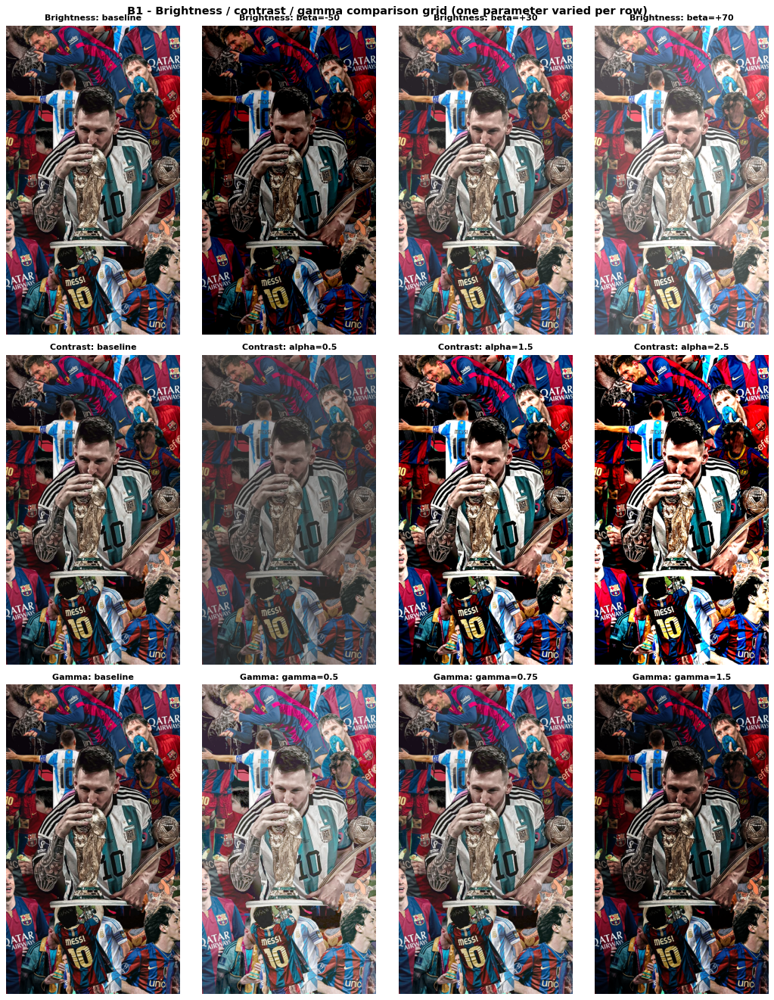

Operation   setting         mean  std (RMS contrast)  % clipped 0  % clipped 255  PSNR dB
Baseline    -              76.90               62.22         0.11           0.01      inf
Brightness  beta=-50       38.02               52.81        44.81           0.00    15.71
Brightness  beta=+30      106.67               61.64         0.00           2.11    18.64
Brightness  beta=+70      144.61               57.31         0.00           8.86    11.44
Contrast    alpha=0.5      76.70               31.11         0.00           0.00    18.27
Contrast    alpha=1.5      78.99               84.17        23.51           6.73    20.64
Contrast    alpha=2.5      83.19               99.99        41.72          16.78    15.25
Gamma       gamma=0.5     127.94               56.90         0.11           0.01    13.67
Gamma       gamma=0.75     97.39               61.78         0.11           0.01    21.52
Gamma       gamma=1.5      52.13               58.61         0.88           0.01    19.55


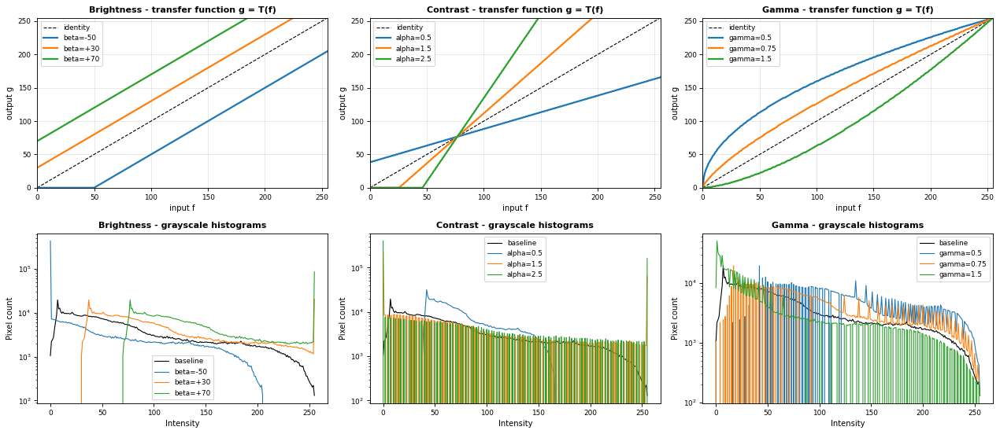

In [ ]:
def adjust_brightness(img, beta):
    return to_u8(img.astype(np.float64) + beta)

def adjust_contrast(img, alpha, pivot=None):
    pivot = float(img.mean()) if pivot is None else pivot
    return to_u8(alpha * (img.astype(np.float64) - pivot) + pivot)

def gamma_correct(img, gamma):
    return to_u8(255.0 * (img.astype(np.float64) / 255.0) ** gamma)

mu_gray = float(gray.mean())     # one pivot for all channels -> no hue shift
ops = {
    'Brightness': [(f"beta={b:+d}", lambda im, b=b: adjust_brightness(im, b)) for b in P['brightness_betas']],
    'Contrast'  : [(f"alpha={a}",   lambda im, a=a: adjust_contrast(im, a, mu_gray)) for a in P['contrast_alphas']],
    'Gamma'     : [(f"gamma={g}",   lambda im, g=g: gamma_correct(im, g)) for g in P['gammas']],
}

imgs, titles = [], []
for op, settings in ops.items():
    imgs.append(img_rgb); titles.append(f"{op}: baseline")
    for lbl, fn in settings:
        imgs.append(fn(img_rgb)); titles.append(f"{op}: {lbl}")
show_grid(imgs, titles, cols=4, panel=(3.3, 5.6),
          suptitle="B1 - Brightness / contrast / gamma comparison grid (one parameter varied per row)")

print(f"{'Operation':11s} {'setting':12s} {'mean':>7} {'std (RMS contrast)':>19} {'% clipped 0':>12} {'% clipped 255':>14} {'PSNR dB':>8}")
bc_results = {}
print(f"{'Baseline':11s} {'-':12s} {gray.mean():7.2f} {gray.std():19.2f} {100*np.mean(gray==0):12.2f} {100*np.mean(gray==255):14.2f} {'inf':>8}")
for op, settings in ops.items():
    for lbl, fn in settings:
        g = fn(gray); bc_results[(op, lbl)] = g
        print(f"{op:11s} {lbl:12s} {g.mean():7.2f} {g.std():19.2f} {100*np.mean(g==0):12.2f} "
              f"{100*np.mean(g==255):14.2f} {psnr(gray, g):8.2f}")

# Transfer functions + histograms
x = np.arange(256)
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, (op, settings) in enumerate(ops.items()):
    ax = axes[0, j]
    ax.plot(x, x, 'k--', lw=1, label='identity')
    for lbl, fn in settings:
        ax.plot(x, fn(x.astype(np.uint8)[None, :])[0], lw=2, label=lbl)
    ax.set_title(f"{op} - transfer function g = T(f)"); ax.set_xlabel('input f'); ax.set_ylabel('output g')
    ax.set_xlim(0, 255); ax.set_ylim(0, 255); ax.legend(fontsize=8); ax.grid(alpha=.3)
    ax = axes[1, j]
    ax.plot(np.bincount(gray.ravel(), minlength=256), 'k', lw=1, label='baseline')
    for lbl, fn in settings:
        ax.plot(np.bincount(fn(gray).ravel(), minlength=256), lw=1, label=lbl)
    ax.set_title(f"{op} - grayscale histograms"); ax.set_xlabel('Intensity'); ax.set_ylabel('Pixel count')
    ax.set_yscale('log'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Analysis**
* **Brightness** ($g=f+\beta$) shifts the histogram rigidly; the mean moves by ≈ β while σ stays ≈ 62 *until clipping*. With $\beta=+70$, 8.9 % of pixels saturate at 255 (white shirt stripes and trophy highlights lose texture) and σ drops to 57; with $\beta=-50$, **44.8 %** of this already-dark image is crushed to 0. Clipping is **irreversible** information loss.
* **Contrast** ($g=\alpha(f-\mu)+\mu$) scales the histogram width around the fixed mean (μ stays ≈ 77–83): $\alpha=0.5$ halves σ (62 → 31) and the image looks flat and washed-out; $\alpha=1.5$ raises σ to 84 and makes objects pop, **but because the image is dark, 23.5 % of pixels are already pushed to 0** (shadow detail in hair and dark shirts disappears); $\alpha=2.5$ clips 41.7 % to black and 16.8 % to white, destroying most tonal detail even though edges look "punchier".
* **Gamma** is non-linear: $\gamma<1$ expands dark values (slope $>1$ near 0) while compressing bright ones. $\gamma=0.5$ raises the mean from 77 to 128 with **no extra clipping at either end** (0.10 % / 0.01 %, the same as the original) — exactly what an under-exposed, low-light frame needs. This is why the integrated pipeline (Part E) uses gamma rather than a plain offset.
* **Justification of choices:** a uniform offset cannot fix a low-light image because it raises noise and black level equally and clips highlights; strong linear contrast gains clip a dark image quickly. For this image $\gamma\approx0.6$–$0.75$, optionally with a mild stretch, gives the best visual result with negligible clipping.
* **Note on PSNR here:** every setting lowers PSNR because the reference is the unmodified image — PSNR measures *difference*, not *quality* (see D2).
* `cv2.convertScaleAbs(f, alpha, beta)` implements $|\alpha f+\beta|$ with saturation; the explicit NumPy versions are used so the mathematics is visible and the pivot can be controlled.

## B2. Noise models and spatial filtering (2 marks)
**Noise models**
* **Gaussian (additive, signal-independent):** $g = f + n,\ n\sim\mathcal N(0,\sigma^2)$, $\sigma=20$ — models thermal/sensor noise (dominant in low light).
* **Salt-and-pepper (impulse):** each pixel is replaced by 0 or 255 with probability $p/2$ each, $p=0.05$ — models dead pixels / transmission bit errors.

**Filters** (identical 3 × 3 support for a fair comparison):
* **Mean (box):** $\hat f = \frac{1}{k^2}\sum_{(s,t)\in W} g(s,t)$ — noise variance reduced by $k^2$.
* **Gaussian:** weights $w(s,t)\propto e^{-(s^2+t^2)/2\sigma^2}$; residual noise $\sigma_{out}=\sigma\sqrt{\sum w^2}$.
* **Median:** $\hat f = \mathrm{median}\{g(s,t)\}$ — non-linear; outliers sit at the ends of the sorted list and are never selected while fewer than half of the window is corrupted.
* **Bilateral:** Gaussian in space *and* in intensity difference — averages only similar pixels, so edges are preserved.

Noise: Gaussian sigma=20, S&P density=0.05; filters: 3x3, Gaussian sigma=0.8
Noise            Filter          MSE  PSNR dB   SSIM
Gaussian noise   (none)        359.9    22.57  0.538
                 Mean          192.2    25.29  0.775
                 Gaussian      141.5    26.62  0.785
                 Median        179.8    25.58  0.738
                 Bilateral     128.8    27.03  0.752
Salt & pepper    (none)       1122.5    17.63  0.491
                 Mean          297.2    23.40  0.670
                 Gaussian      275.7    23.73  0.678
                 Median        107.8    27.80  0.923
                 Bilateral    1064.8    17.86  0.494


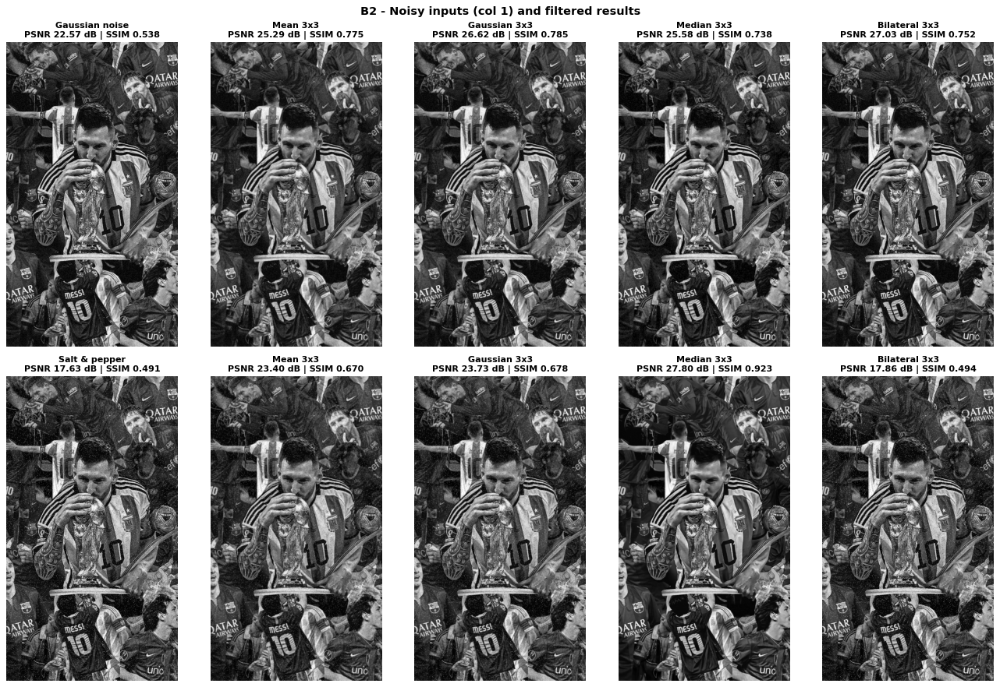

In [ ]:
def add_gaussian_noise(img, sigma, seed=SEED):
    rng = np.random.default_rng(seed)
    return to_u8(img.astype(np.float64) + rng.normal(0, sigma, img.shape))

def add_salt_pepper(img, density, seed=SEED):
    rng = np.random.default_rng(seed)
    r = rng.random(img.shape)
    out = img.copy()
    out[r < density / 2] = 0                          # pepper
    out[(r >= density / 2) & (r < density)] = 255     # salt
    return out

k, gs = P['filter_ksize'], P['gauss_filter_sigma']
def apply_filter(img, name, k=k, gs=gs):
    if name == 'Mean':      return cv2.blur(img, (k, k))
    if name == 'Gaussian':  return cv2.GaussianBlur(img, (k, k), gs)
    if name == 'Median':    return cv2.medianBlur(img, k)
    if name == 'Bilateral': return cv2.bilateralFilter(img, k, 50, k)
    raise ValueError(name)

FILTERS = ['Mean', 'Gaussian', 'Median', 'Bilateral']
noisy = {'Gaussian noise': add_gaussian_noise(gray, P['gauss_noise_sigma']),
         'Salt & pepper':  add_salt_pepper(gray, P['sp_density'])}
filtered = {(nz, fl): apply_filter(im, fl) for nz, im in noisy.items() for fl in FILTERS}

print(f"Noise: Gaussian sigma={P['gauss_noise_sigma']}, S&P density={P['sp_density']}; "
      f"filters: {k}x{k}, Gaussian sigma={gs}")
print(f"{'Noise':16s} {'Filter':10s} {'MSE':>8} {'PSNR dB':>8} {'SSIM':>6}")
for nz, im in noisy.items():
    print(f"{nz:16s} {'(none)':10s} {mse(gray, im):8.1f} {psnr(gray, im):8.2f} {ssim(gray, im):6.3f}")
    for fl in FILTERS:
        r = filtered[(nz, fl)]
        print(f"{'':16s} {fl:10s} {mse(gray, r):8.1f} {psnr(gray, r):8.2f} {ssim(gray, r):6.3f}")

imgs, titles = [], []
for nz, im in noisy.items():
    imgs.append(im); titles.append(f"{nz}\n{metric_str(gray, im)}")
    for fl in FILTERS:
        imgs.append(filtered[(nz, fl)]); titles.append(f"{fl} {k}x{k}\n{metric_str(gray, filtered[(nz, fl)])}")
show_grid(imgs, titles, cols=5, panel=(3.3, 5.6), suptitle="B2 - Noisy inputs (col 1) and filtered results")

zy, zx = slice(640, 820), slice(380, 560)    # jersey number "10": strong edges
imgs, titles = [], []
for nz, im in noisy.items():
    imgs += [gray[zy, zx], im[zy, zx]] + [filtered[(nz, fl)][zy, zx] for fl in FILTERS]
    titles += ["Clean", nz] + [f"{fl} | {psnr(gray, filtered[(nz, fl)]):.1f} dB" for fl in FILTERS]
show_grid(imgs, titles, cols=6, panel=(2.8, 3.4), suptitle="B2 - Zoom on the '10': noise removal vs edge preservation")

Mean    : predicted residual noise sigma = 6.67, measured = 6.49
Gaussian: predicted residual noise sigma = 7.73, measured = 7.48
cv2.medianBlur == scipy.ndimage.median_filter : True
Gaussian noise  Gaussian  PSNR for k=[3, 5, 7, 9, 11]: 26.50, 24.82, 22.99, 22.03, 21.26
Gaussian noise  Median    PSNR for k=[3, 5, 7, 9, 11]: 25.58, 22.90, 21.21, 20.10, 19.26
Gaussian noise  Mean      PSNR for k=[3, 5, 7, 9, 11]: 25.29, 21.92, 20.32, 19.34, 18.63
Salt & pepper   Gaussian  PSNR for k=[3, 5, 7, 9, 11]: 23.78, 23.45, 22.31, 21.57, 20.91
Salt & pepper   Median    PSNR for k=[3, 5, 7, 9, 11]: 27.80, 23.40, 21.42, 20.19, 19.28
Salt & pepper   Mean      PSNR for k=[3, 5, 7, 9, 11]: 23.40, 21.41, 20.06, 19.16, 18.49


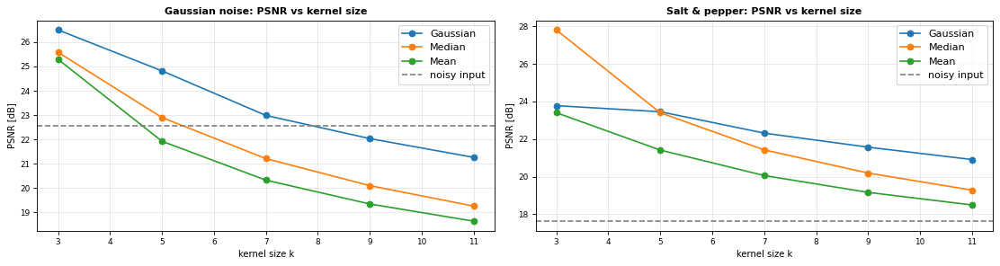

In [ ]:
# Theory check: residual noise of the LINEAR filters (filter is linear -> filtered(noisy) - filtered(clean) = filtered(noise))
gn = noisy['Gaussian noise']
g_kernel = cv2.getGaussianKernel(k, gs); w2d = g_kernel @ g_kernel.T
pred = {'Mean': P['gauss_noise_sigma'] / k, 'Gaussian': P['gauss_noise_sigma'] * np.sqrt((w2d ** 2).sum())}
for fl in ['Mean', 'Gaussian']:
    meas = (apply_filter(gn, fl).astype(float) - apply_filter(gray, fl).astype(float)).std()
    print(f"{fl:8s}: predicted residual noise sigma = {pred[fl]:.2f}, measured = {meas:.2f}")

# Cross-check OpenCV's median with SciPy's (same replicate border)
sp = noisy['Salt & pepper']
same = np.array_equal(cv2.medianBlur(sp, 5), ndimage.median_filter(sp, size=5, mode='nearest'))
print(f"cv2.medianBlur == scipy.ndimage.median_filter : {same}")

# Controlled kernel-size sweep (only k varies; Gaussian sigma = 0.3*((k-1)*0.5-1)+0.8, OpenCV's rule)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (nz, im) in zip(axes, noisy.items()):
    for fl, fn in [('Gaussian', lambda z, kk: cv2.GaussianBlur(z, (kk, kk), 0)),
                   ('Median',   lambda z, kk: cv2.medianBlur(z, kk)),
                   ('Mean',     lambda z, kk: cv2.blur(z, (kk, kk)))]:
        vals = [psnr(gray, fn(im, kk)) for kk in P['ksize_sweep']]
        print(f"{nz:15s} {fl:9s} PSNR for k={P['ksize_sweep']}: " + ", ".join(f"{v:.2f}" for v in vals))
        ax.plot(P['ksize_sweep'], vals, 'o-', label=fl)
    ax.axhline(psnr(gray, im), color='gray', ls='--', label='noisy input')
    ax.set_title(f"{nz}: PSNR vs kernel size"); ax.set_xlabel('kernel size k'); ax.set_ylabel('PSNR [dB]')
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

**Effectiveness comparison** (all filters 3 × 3)
* **Gaussian noise (input 22.57 dB, SSIM 0.54):** every filter helps. The residual noise of the linear filters matches theory (mean: predicted σ 6.67, measured 6.49; Gaussian: 7.73 vs 7.48). The **Gaussian** filter gives the best SSIM (0.785, 26.62 dB) because its smooth weights blur least; the **bilateral** filter gives the best PSNR (27.03 dB) and the crispest edges on the "10", but leaves some grain inside textured areas (SSIM 0.752). The median (25.58 dB) is the weakest here — Gaussian noise has no outliers for it to reject, and it produces a slightly blotchy texture.
* **Salt-and-pepper noise (input 17.63 dB, SSIM 0.49):** the linear filters only **spread** each impulse into a grey blob (Gaussian 23.73 dB, mean 23.40 dB). The **median filter removes almost every impulse** — 27.80 dB and SSIM **0.923**, by far the best — while keeping edges sharp (the median of a step edge is still a step). The bilateral filter fails completely (17.86 dB): impulses differ so much in intensity that its range kernel treats them as "edges" and preserves them.
* **Kernel size (controlled sweep):** PSNR falls monotonically from k = 3 to 11 for every filter and both noise types (e.g. median on S&P: 27.80 → 19.28 dB). This collage is full of fine texture (hair, tattoos, text), so larger windows remove real detail faster than they remove noise. This is why `filter_ksize = 3`.
* **Conclusion for the pipeline:** median for impulse noise; Gaussian or bilateral for sensor (Gaussian) noise. Bilateral is used in Part E because the goal is to preserve edges and object boundaries.

## B3. Sobel and Laplacian operators (2 marks)
**First-order (gradient) — Sobel.** Derivative along one axis combined with smoothing along the other:
$$K_x=\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix} = \begin{bmatrix}1\\2\\1\end{bmatrix}\begin{bmatrix}-1&0&1\end{bmatrix},\quad K_y=K_x^T,\quad
|\nabla f|=\sqrt{G_x^2+G_y^2},\quad \theta=\operatorname{atan2}(G_y,G_x)$$

**Second-order — Laplacian.** $\nabla^2 f = \frac{\partial^2 f}{\partial x^2}+\frac{\partial^2 f}{\partial y^2}\approx f(x+1,y)+f(x-1,y)+f(x,y+1)+f(x,y-1)-4f(x,y)$, kernel $\begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}$. Because it amplifies noise, it is usually applied after Gaussian smoothing → **Laplacian of Gaussian (LoG)**, whose zero-crossings mark edges.

Outputs are computed in `float64` (`CV_64F`) — in `uint8` the negative half of each response would be clipped to 0.

max |cv2.Sobel - explicit Kx (scipy.ndimage.correlate)| : 0.0
max |cv2.Laplacian - explicit kernel (cv2.filter2D)|    : 0.0


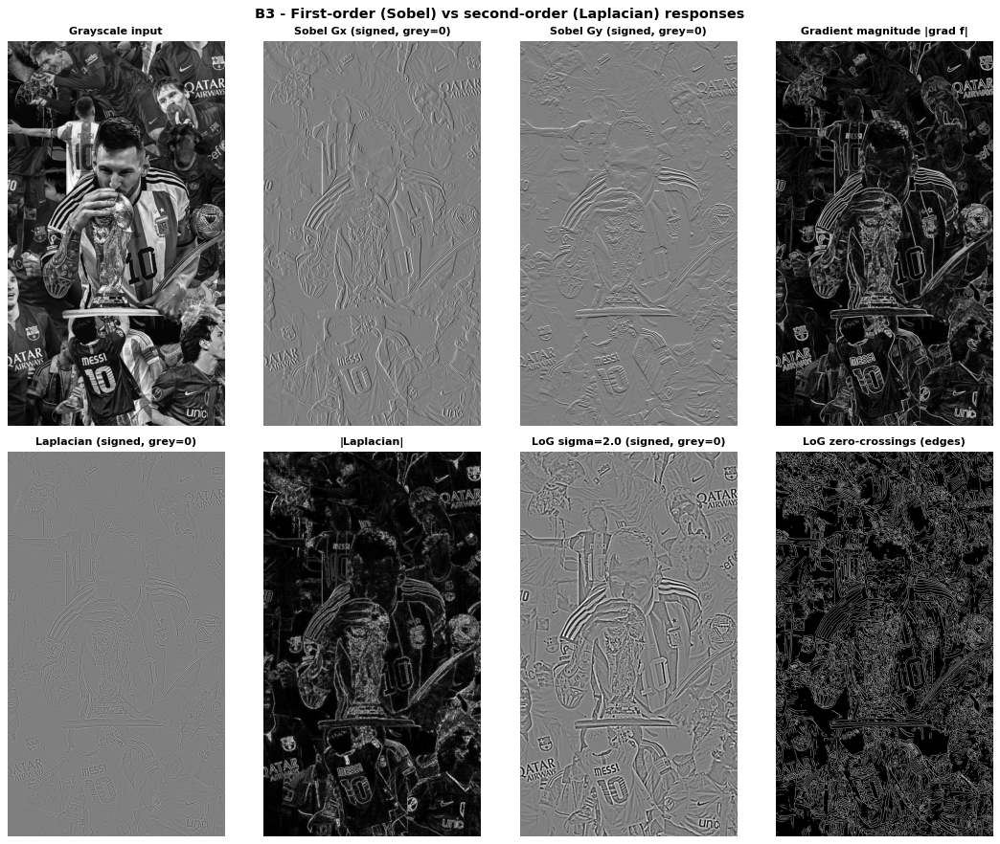

In [ ]:
gf = gray.astype(np.float64)
Gx = cv2.Sobel(gf, cv2.CV_64F, 1, 0, ksize=P['sobel_ksize'])
Gy = cv2.Sobel(gf, cv2.CV_64F, 0, 1, ksize=P['sobel_ksize'])
mag = np.hypot(Gx, Gy)
lap = cv2.Laplacian(gf, cv2.CV_64F, ksize=P['lap_ksize'])
log_ = cv2.Laplacian(cv2.GaussianBlur(gf, (0, 0), P['log_sigma']), cv2.CV_64F, ksize=P['lap_ksize'])

# Verify the built-ins against the explicit kernels (OpenCV/SciPy both use correlation; REFLECT_101 == 'mirror')
Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)
Kl = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float)
print("max |cv2.Sobel - explicit Kx (scipy.ndimage.correlate)| :",
      np.abs(Gx - ndimage.correlate(gf, Kx, mode='mirror')).max())
print("max |cv2.Laplacian - explicit kernel (cv2.filter2D)|    :",
      np.abs(lap - cv2.filter2D(gf, cv2.CV_64F, Kl)).max())

# Zero crossings of LoG = edge locations (sign change with a minimum slope to reject flat-area noise)
zc = np.zeros_like(gray, np.uint8)
thr = 0.02 * np.abs(log_).max()
sh = np.sign(log_)
zc[:, :-1] |= ((sh[:, :-1] * sh[:, 1:] < 0) & (np.abs(log_[:, :-1] - log_[:, 1:]) > thr)).astype(np.uint8)
zc[:-1, :] |= ((sh[:-1, :] * sh[1:, :] < 0) & (np.abs(log_[:-1, :] - log_[1:, :]) > thr)).astype(np.uint8)

def sym(z):   # symmetric limits for signed responses
    v = np.percentile(np.abs(z), 99.5); return np.clip(z, -v, v)

show_grid([gray, sym(Gx), sym(Gy), np.clip(mag, 0, np.percentile(mag, 99.5)),
           sym(lap), np.clip(np.abs(lap), 0, np.percentile(np.abs(lap), 99.5)), sym(log_), zc * 255],
          ["Grayscale input", "Sobel Gx (signed, grey=0)", "Sobel Gy (signed, grey=0)", "Gradient magnitude |grad f|",
           "Laplacian (signed, grey=0)", "|Laplacian|", f"LoG sigma={P['log_sigma']} (signed, grey=0)", "LoG zero-crossings (edges)"],
          cols=4, panel=(3.4, 5.6), raw_range=False,
          cmaps=['gray'] * 8,
          suptitle="B3 - First-order (Sobel) vs second-order (Laplacian) responses")

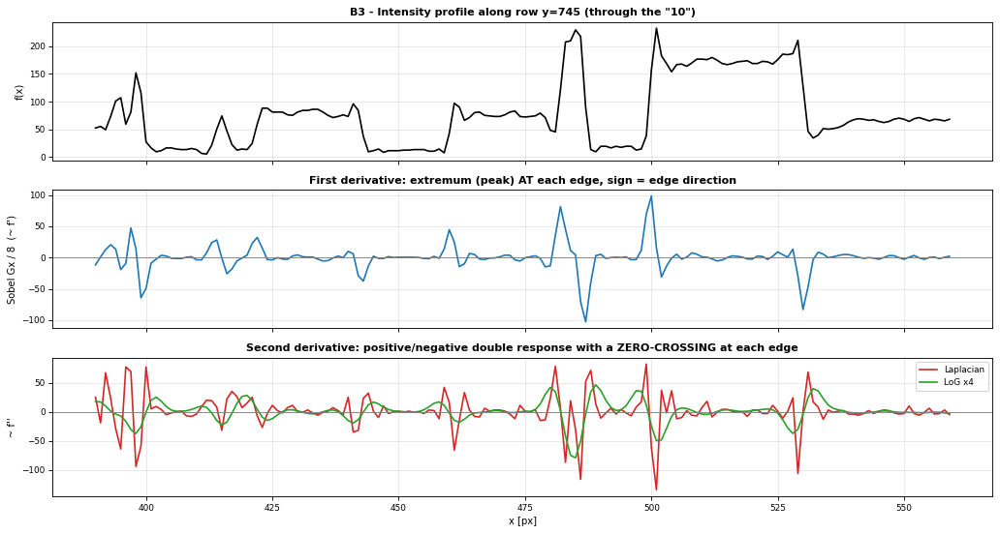

Relative noise in the response  = std(response_noisy - response_clean) / std(response_clean):
  Sobel magnitude : 0.219
  Laplacian       : 1.023
  LoG (sigma=2.0)   : 0.112


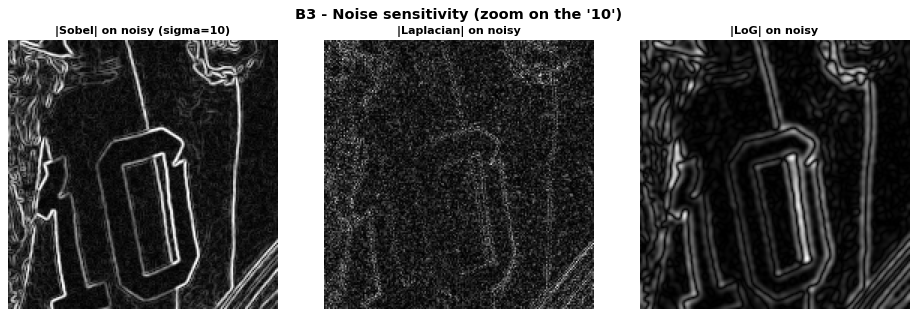

In [ ]:
# 1-D profile across the jersey number: f, first derivative, second derivative
row, xs = 745, slice(390, 560)
xr = np.arange(xs.start, xs.stop)
prof = gf[row, xs]
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
axes[0].plot(xr, prof, 'k'); axes[0].set_ylabel('f(x)'); axes[0].set_title(f'B3 - Intensity profile along row y={row} (through the "10")')
axes[1].plot(xr, Gx[row, xs] / 8, 'tab:blue'); axes[1].axhline(0, color='gray', lw=.8)
axes[1].set_ylabel("Sobel Gx / 8  (~ f')"); axes[1].set_title('First derivative: extremum (peak) AT each edge, sign = edge direction')
axes[2].plot(xr, lap[row, xs], 'tab:red', label='Laplacian'); axes[2].plot(xr, log_[row, xs] * 4, 'tab:green', label='LoG x4')
axes[2].axhline(0, color='gray', lw=.8); axes[2].legend(fontsize=8)
axes[2].set_ylabel("~ f''"); axes[2].set_xlabel('x [px]')
axes[2].set_title('Second derivative: positive/negative double response with a ZERO-CROSSING at each edge')
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Noise sensitivity: same operators on a mildly noisy image (sigma=10)
noisy10 = add_gaussian_noise(gray, 10).astype(np.float64)
mag_n = np.hypot(cv2.Sobel(noisy10, cv2.CV_64F, 1, 0, ksize=3), cv2.Sobel(noisy10, cv2.CV_64F, 0, 1, ksize=3))
lap_n = cv2.Laplacian(noisy10, cv2.CV_64F, ksize=1)
log_n = cv2.Laplacian(cv2.GaussianBlur(noisy10, (0, 0), P['log_sigma']), cv2.CV_64F, ksize=1)
ratio = lambda clean, nz: (nz - clean).std() / clean.std()
print("Relative noise in the response  = std(response_noisy - response_clean) / std(response_clean):")
print(f"  Sobel magnitude : {ratio(mag, mag_n):.3f}")
print(f"  Laplacian       : {ratio(lap, lap_n):.3f}")
print(f"  LoG (sigma={P['log_sigma']})   : {ratio(log_, log_n):.3f}")
show_grid([np.clip(mag_n, 0, np.percentile(mag_n, 99.5))[zy, zx], np.abs(lap_n)[zy, zx], np.abs(log_n)[zy, zx]],
          ["|Sobel| on noisy (sigma=10)", "|Laplacian| on noisy", "|LoG| on noisy"], cols=3, panel=(4, 4),
          raw_range=False, suptitle="B3 - Noise sensitivity (zoom on the '10')")

**First-order vs second-order derivative operators**
| Aspect | Sobel (1st order) | Laplacian (2nd order) |
|---|---|---|
| Response at an edge | single **peak** (extremum) of $|\nabla f|$ | **double** response (+/−) with a **zero-crossing** at the edge centre |
| Direction | gives magnitude **and orientation** ($G_x$, $G_y$ separately) | **isotropic** — one scalar, no orientation |
| Edge width | thick edges (several pixels) | thin, precisely localised (zero-crossings) |
| Noise | built-in smoothing (the [1 2 1] factor) → robust | amplifies high frequencies ∝ $\omega^2$ → very noise-sensitive |
| Constant / ramp regions | 0 / constant | 0 / 0 (responds only to *changes of slope*) |

* The profile plot shows this directly: each black/white transition of the "10" produces one peak in $G_x$ but a +/− pair in the Laplacian whose zero-crossing sits exactly at the edge.
* The noise test quantifies the sensitivity: the relative noise in the raw Laplacian response is **1.02** (noise as strong as the signal) versus **0.22** for the Sobel magnitude — almost 5× larger — and Gaussian pre-smoothing (LoG, σ = 2) brings it down to 0.11 — which is why LoG, not the raw Laplacian, should be used on low-quality inputs.
* **In the pipeline**, Sobel magnitude is the better "edge-strength" feature (and is used in Part E to measure edge preservation); the Laplacian/high-pass response is useful for **sharpening** ($g = f - c\nabla^2 f$, i.e. high-boost in Part C).

---
# Part C — Frequency-Domain Filtering (5 marks)
## C1. 2-D Fourier transform and log-magnitude spectrum (2 marks)
$$F(u,v)=\sum_{x=0}^{M-1}\sum_{y=0}^{N-1} f(x,y)\,e^{-j2\pi\left(\frac{ux}{M}+\frac{vy}{N}\right)},\qquad |F(u,v)|=\sqrt{\mathrm{Re}^2+\mathrm{Im}^2}$$
Computed with the FFT in $O(MN\log MN)$. $F(0,0)=\sum f$ is the DC term (average brightness × number of pixels).

Image size M x N = (1308, 736), spectrum dtype = complex128
DC term F(0,0) = 74,029,664  ==  sum of pixels = 74,029,664  (mean 76.90 x 962,688 px)
Linear magnitude: max = 7.403e+07, median = 7.778e+03, ratio = 9,518 : 1
Log magnitude   : max = 18.12, median = 8.96, ratio = 2.02 : 1
Hermitian symmetry (real image): max |F(u,v) - conj F(-u,-v)| = 1.86e-09


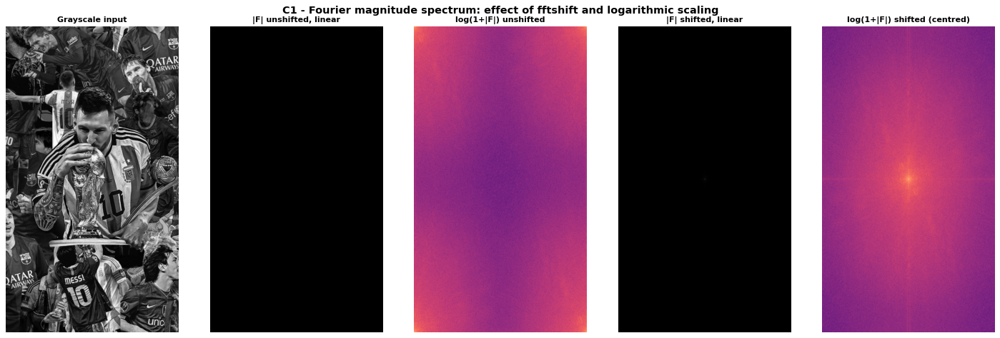

In [ ]:
F = np.fft.fft2(gf)
Fs = np.fft.fftshift(F)
mag_unshift, mag_shift = np.abs(F), np.abs(Fs)
logmag = np.log1p(mag_shift)          # log(1 + |F|): the +1 avoids log(0)

print(f"Image size M x N = {gray.shape}, spectrum dtype = {F.dtype}")
print(f"DC term F(0,0) = {F[0,0].real:,.0f}  ==  sum of pixels = {gf.sum():,.0f}  (mean {gf.mean():.2f} x {gf.size:,} px)")
print(f"Linear magnitude: max = {mag_shift.max():.3e}, median = {np.median(mag_shift):.3e}, "
      f"ratio = {mag_shift.max()/np.median(mag_shift):,.0f} : 1")
print(f"Log magnitude   : max = {logmag.max():.2f}, median = {np.median(logmag):.2f}, ratio = {logmag.max()/np.median(logmag):.2f} : 1")
print(f"Hermitian symmetry (real image): max |F(u,v) - conj F(-u,-v)| = "
      f"{np.abs(F - np.conj(np.roll(np.flip(F), 1, axis=(0, 1)))).max():.2e}")

fig, axes = plt.subplots(1, 5, figsize=(18, 6))
items = [(gray, 'Grayscale input', 'gray'),
         (mag_unshift, '|F| unshifted, linear', 'gray'), (np.log1p(mag_unshift), 'log(1+|F|) unshifted', 'magma'),
         (mag_shift, '|F| shifted, linear', 'gray'), (logmag, 'log(1+|F|) shifted (centred)', 'magma')]
for ax, (im, t, cm) in zip(axes, items):
    ax.imshow(im, cmap=cm); ax.set_title(t); ax.axis('off')
fig.suptitle('C1 - Fourier magnitude spectrum: effect of fftshift and logarithmic scaling'); plt.tight_layout(); plt.show()

**Why shift?** The FFT returns frequencies in the order $0,1,\dots,M/2-1,-M/2,\dots,-1$, so the DC term and low frequencies sit in the **four corners** (see "unshifted"). `np.fft.fftshift` swaps quadrants (equivalently multiplying $f(x,y)$ by $(-1)^{x+y}$ before the transform) so that DC is at the **centre** and frequency increases radially outward. This makes the spectrum interpretable — low frequencies (smooth shading) at the centre, high frequencies (edges, texture, noise) at the periphery — and lets filters be designed as simple functions of the distance $D(u,v)$ from the centre. Shifting changes only the display/indexing, not the information; it must be undone with `ifftshift` before the inverse transform.

**Why logarithmic scaling?** The dynamic range is enormous: the DC term ($7.4\times10^7$) is ≈ 9 500 times larger than the median coefficient. On a linear display only the single bright DC dot is visible and everything else is black. $\log(1+|F|)$ compresses this to about 2 : 1, revealing the structure: the bright cross through the centre comes from the **image borders** (the DFT treats the image as periodic, so the left/right and top/bottom edges form artificial discontinuities) and from the many horizontal/vertical edges of the collage tiles; energy decays rapidly with radius, as for all natural images ($|F|\propto 1/\omega$ approximately).

## C2. Low-pass and high-pass filter design (2 marks)
Filtering in the frequency domain is a point-wise product: $G(u,v)=H(u,v)\,F(u,v)$, then $g=\mathrm{Re}\{\mathcal F^{-1}[G]\}$. With $D(u,v)=\sqrt{(u-M/2)^2+(v-N/2)^2}$ (distance from the centred DC):

* **Gaussian low-pass (main design):** $H_{LP}(u,v)=e^{-D^2(u,v)/2D_0^2}$, $D_0=60$
* **Gaussian high-pass:** $H_{HP}=1-H_{LP}$ with its own cut-off, $D_0=30$
* **High-boost (sharpening, enhancement use of the HPF):** $g = f + k\,g_{HP}$, $k=1.5$
* **Ideal low-pass (for comparison only):** $H=1$ if $D\le D_0$ else 0 — sharp cut-off → **ringing** (its spatial kernel is a sinc).

Gaussian filters are chosen because a Gaussian transforms to a Gaussian — smooth in both domains, so **no ringing** artefacts. $H$ is real and symmetric, so the output is real (imaginary residue ≈ 1e-13, verified).

Max |imag| after inverse FFT: LPF 6.2e-14, HPF 9.9e-14 -> output is real
Spectral energy kept: Gaussian LPF 88.37 %, Gaussian HPF 11.502 %, Ideal LPF 90.69 %
HPF output mean = -6.80e-17 (DC removed), range [-158.0, 198.8]
Gaussian LPF  : PSNR 20.01 dB | SSIM 0.593
Ideal LPF     : PSNR 18.55 dB | SSIM 0.443
High-boost k=1.5: PSNR 18.27 dB | SSIM 0.713


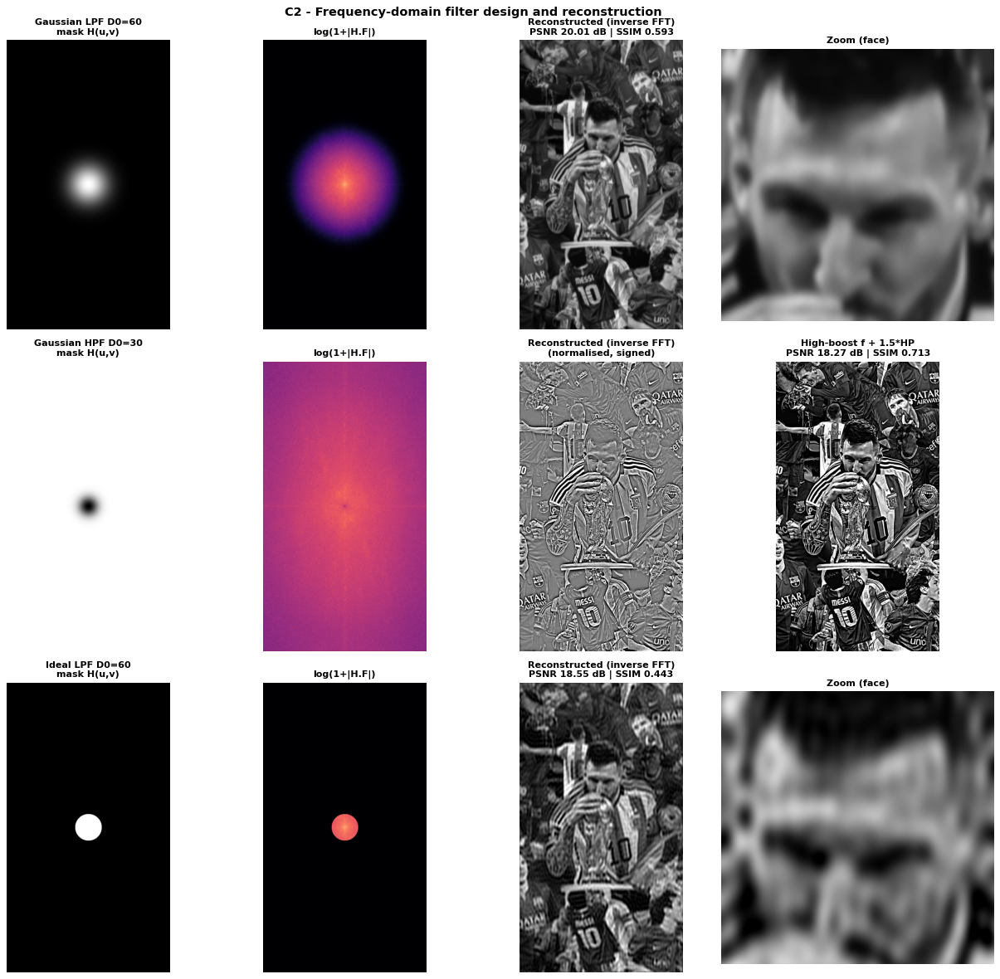

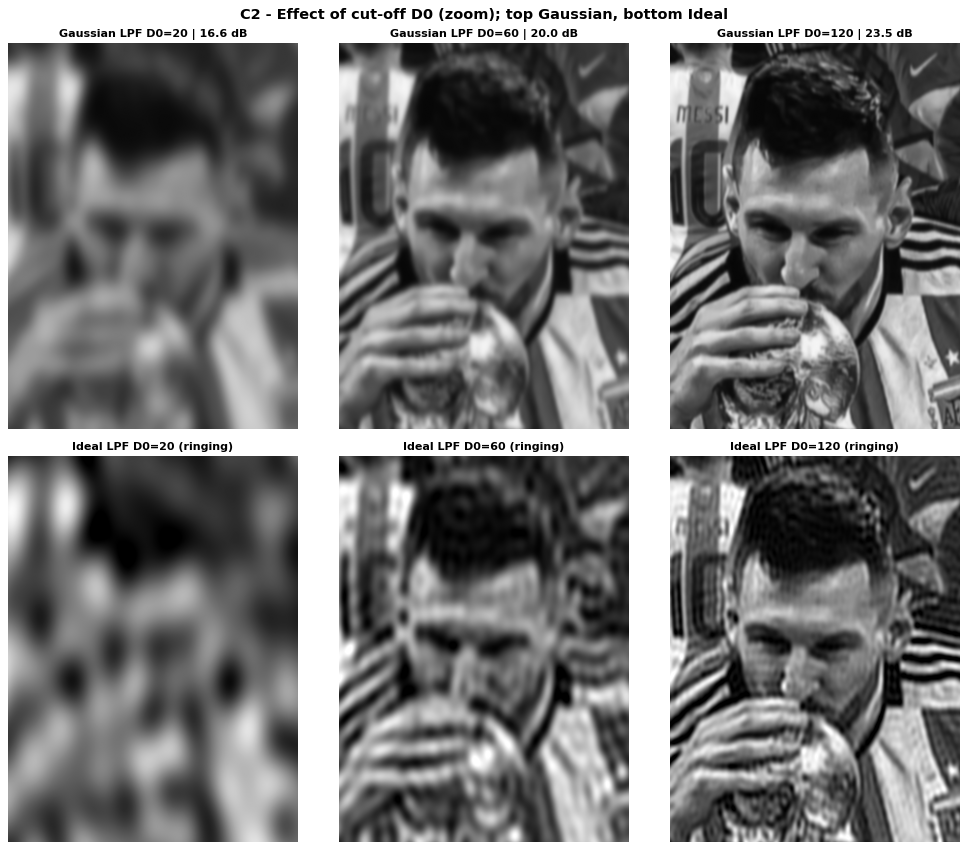

In [ ]:
def dist_grid(shape):
    M, N = shape
    u = np.arange(M) - M // 2
    v = np.arange(N) - N // 2
    V, U = np.meshgrid(v, u)
    return np.sqrt(U ** 2 + V ** 2)

def gaussian_lp(shape, D0): return np.exp(-dist_grid(shape) ** 2 / (2 * D0 ** 2))
def gaussian_hp(shape, D0): return 1 - gaussian_lp(shape, D0)
def ideal_lp(shape, D0):    return (dist_grid(shape) <= D0).astype(np.float64)

def freq_filter(img, Hmask):
    # Returns (real output image, filtered centred spectrum, max |imag| residue)
    Fc = np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))
    Gc = Fc * Hmask
    g = np.fft.ifft2(np.fft.ifftshift(Gc))
    return g.real, Gc, np.abs(g.imag).max()

D0l, D0h, kb = P['D0_lp'], P['D0_hp'], P['highboost_k']
H_lp, H_hp, H_id = gaussian_lp(gray.shape, D0l), gaussian_hp(gray.shape, D0h), ideal_lp(gray.shape, D0l)
lp_out, G_lp, im_lp = freq_filter(gray, H_lp)
hp_out, G_hp, im_hp = freq_filter(gray, H_hp)
id_out, G_id, _     = freq_filter(gray, H_id)
highboost = to_u8(gf + kb * hp_out)
lp_u8 = to_u8(lp_out)
energy = lambda G: (np.abs(G) ** 2).sum() / (np.abs(Fs) ** 2).sum()

print(f"Max |imag| after inverse FFT: LPF {im_lp:.1e}, HPF {im_hp:.1e} -> output is real")
print(f"Spectral energy kept: Gaussian LPF {100*energy(G_lp):.2f} %, Gaussian HPF {100*energy(G_hp):.3f} %, "
      f"Ideal LPF {100*energy(G_id):.2f} %")
print(f"HPF output mean = {hp_out.mean():.2e} (DC removed), range [{hp_out.min():.1f}, {hp_out.max():.1f}]")
print(f"Gaussian LPF  : {metric_str(gray, lp_u8)}")
print(f"Ideal LPF     : {metric_str(gray, to_u8(id_out))}")
print(f"High-boost k={kb}: {metric_str(gray, highboost)}")

fig, axes = plt.subplots(3, 4, figsize=(16, 15))
rows = [(f"Gaussian LPF D0={D0l}", H_lp, G_lp, lp_u8, None),
        (f"Gaussian HPF D0={D0h}", H_hp, G_hp, norm_u8(np.clip(hp_out, -60, 60)), highboost),
        (f"Ideal LPF D0={D0l}",    H_id, G_id, to_u8(id_out), None)]
for r, (name, Hm, Gc, out, extra) in enumerate(rows):
    axes[r, 0].imshow(Hm, cmap='gray', vmin=0, vmax=1); axes[r, 0].set_title(f"{name}\nmask H(u,v)")
    axes[r, 1].imshow(np.log1p(np.abs(Gc)), cmap='magma', vmin=0, vmax=logmag.max()); axes[r, 1].set_title("log(1+|H.F|)")
    axes[r, 2].imshow(out, cmap='gray', vmin=0, vmax=255); axes[r, 2].set_title("Reconstructed (inverse FFT)" + ("\n(normalised, signed)" if r == 1 else f"\n{metric_str(gray, out)}"))
    if extra is not None:
        axes[r, 3].imshow(extra, cmap='gray', vmin=0, vmax=255); axes[r, 3].set_title(f"High-boost f + {kb}*HP\n{metric_str(gray, extra)}")
    else:
        crop_ = out[330:520, 280:470]
        axes[r, 3].imshow(crop_, cmap='gray', vmin=0, vmax=255); axes[r, 3].set_title("Zoom (face)")
    for c in range(4):
        axes[r, c].axis('off')
fig.suptitle('C2 - Frequency-domain filter design and reconstruction'); plt.tight_layout(); plt.show()

# Controlled sweep of the cut-off D0 (only D0 varies)
outs = [to_u8(freq_filter(gray, gaussian_lp(gray.shape, d))[0]) for d in P['D0_sweep']]
show_grid([o[250:650, 230:530] for o in outs] + [to_u8(freq_filter(gray, ideal_lp(gray.shape, d))[0])[250:650, 230:530] for d in P['D0_sweep']],
          [f"Gaussian LPF D0={d} | {psnr(gray, o):.1f} dB" for d, o in zip(P['D0_sweep'], outs)] +
          [f"Ideal LPF D0={d} (ringing)" for d in P['D0_sweep']],
          cols=3, panel=(4.2, 5.4), suptitle="C2 - Effect of cut-off D0 (zoom); top Gaussian, bottom Ideal")

**Discussion**
* **Low-pass:** removes high frequencies → smoother image, reduced noise/texture, blurred edges. $D_0=60$ keeps **88 % of the spectral energy** yet visibly softens every edge (PSNR 20.0 dB, SSIM 0.59) — energy is concentrated at low frequencies, while visual sharpness lives in the low-energy high frequencies. The sweep confirms the trade-off: smaller $D_0$ = stronger blur and lower PSNR.
* **High-pass:** $H(0,0)=0$ removes the DC component, so the output has zero mean (printed ≈ 1e-17) and carries only 11.5 % of the energy — only edges and texture remain — conceptually the same information as the Laplacian (B3), but with a tunable cut-off. Adding it back (**high-boost**) sharpens boundaries — useful for the "preserve/enhance structure" requirement, but it also boosts noise, so in practice it is applied *after* denoising.
* **Ideal vs Gaussian:** the ideal filter's abrupt cut-off corresponds to a sinc kernel in space → visible **ringing** (ripples parallel to strong edges, e.g. around the hair and shirt stripes in the sweep). At the same $D_0=60$ the ideal LPF scores lower (18.55 dB, SSIM 0.44) than the Gaussian (20.01 dB, 0.59) even though it keeps *more* energy (90.7 %). The Gaussian has no side-lobes, so it is preferred.

## C3. Spatial-domain vs frequency-domain filtering (1 mark)
By the **convolution theorem**, $f*h \Leftrightarrow F\cdot H$. A spatial Gaussian with standard deviation $\sigma$ (pixels) has transform $H(u,v)=\exp\!\big(-\tfrac{u^2}{2\sigma_u^2}-\tfrac{v^2}{2\sigma_v^2}\big)$ with $\sigma_u=\frac{M}{2\pi\sigma},\ \sigma_v=\frac{N}{2\pi\sigma}$. Both versions are applied with $\sigma=4$ px and compared for (i) equality, (ii) noise removal and detail, (iii) run time vs kernel size.

sigma=4.0 px -> spatial kernel 25x25;  frequency sigma_u=52.0, sigma_v=29.3
Max |spatial - frequency| : whole image 89.23, interior (>25px from border) 0.488
PSNR between the two outputs: whole 38.3 dB, interior 69.2 dB

On the Gaussian-noisy image (sigma_n=20):  noisy PSNR 22.57 dB | SSIM 0.538
  spatial Gaussian   : PSNR 18.52 dB | SSIM 0.472
  frequency Gaussian : PSNR 18.46 dB | SSIM 0.469


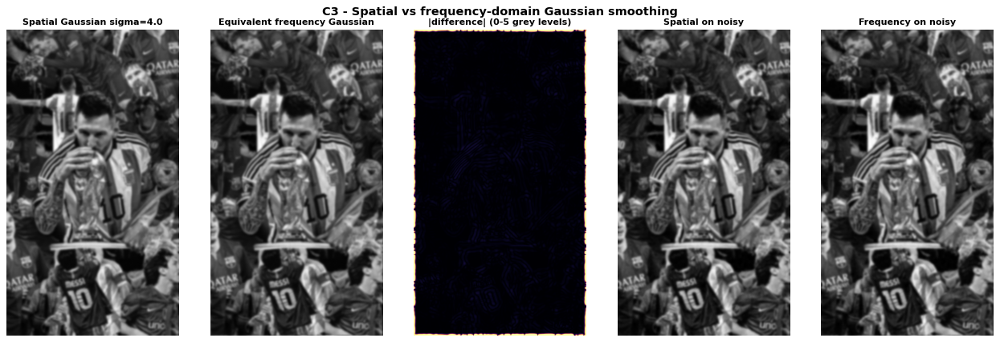

In [ ]:
sig = P['equiv_sigma']
M_, N_ = gray.shape
Dm = dist_grid(gray.shape)   # not used directly; anisotropic version below
uu = (np.arange(M_) - M_ // 2)[:, None]; vv = (np.arange(N_) - N_ // 2)[None, :]
su, sv = M_ / (2 * np.pi * sig), N_ / (2 * np.pi * sig)
H_eq = np.exp(-(uu ** 2) / (2 * su ** 2) - (vv ** 2) / (2 * sv ** 2))

ks = int(2 * np.ceil(3 * sig) + 1)
sp_out = cv2.GaussianBlur(gf, (ks, ks), sig, borderType=cv2.BORDER_REFLECT_101)
fq_out, _, _ = freq_filter(gray, H_eq)
diff = np.abs(sp_out - fq_out)
b = ks
print(f"sigma={sig} px -> spatial kernel {ks}x{ks};  frequency sigma_u={su:.1f}, sigma_v={sv:.1f}")
print(f"Max |spatial - frequency| : whole image {diff.max():.2f}, interior (>{b}px from border) {diff[b:-b, b:-b].max():.3f}")
print(f"PSNR between the two outputs: whole {psnr(sp_out, fq_out):.1f} dB, interior {psnr(sp_out[b:-b, b:-b], fq_out[b:-b, b:-b]):.1f} dB")

gnoisy = noisy['Gaussian noise']
sp_n = to_u8(cv2.GaussianBlur(gnoisy.astype(float), (ks, ks), sig))
fq_n = to_u8(freq_filter(gnoisy, H_eq)[0])
print(f"\nOn the Gaussian-noisy image (sigma_n={P['gauss_noise_sigma']}):  noisy {metric_str(gray, gnoisy)}")
print(f"  spatial Gaussian   : {metric_str(gray, sp_n)}")
print(f"  frequency Gaussian : {metric_str(gray, fq_n)}")

show_grid([to_u8(sp_out), to_u8(fq_out), np.clip(diff, 0, 5), sp_n, fq_n],
          [f"Spatial Gaussian sigma={sig}", "Equivalent frequency Gaussian", "|difference| (0-5 grey levels)",
           "Spatial on noisy", "Frequency on noisy"],
          cols=5, panel=(3.2, 5.4), raw_range=False, cmaps=['gray', 'gray', 'inferno', 'gray', 'gray'],
          suptitle="C3 - Spatial vs frequency-domain Gaussian smoothing")

sigma  kernel  cv2 separable  direct 2-D  FFT (numpy)  scipy fftconvolve   [ms]
    1    7x7            3.81        53.0       132.08              39.30
    2   13x13           5.80       225.2       125.71              38.16
    4   25x25          11.64       807.7       126.65              37.47
    8   49x49          23.47         nan       128.52              42.92
   16   97x97          54.50         nan       142.36              44.11


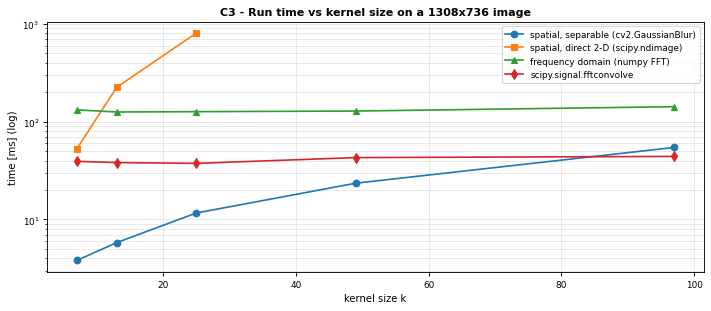

In [ ]:
def timeit(fn, rep=3):
    best = 1e9
    for _ in range(rep):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best * 1000

sigmas = [1, 2, 4, 8, 16]
rows = []
for s_ in sigmas:
    k_ = int(2 * np.ceil(3 * s_) + 1)
    g1 = cv2.getGaussianKernel(k_, s_); K2 = g1 @ g1.T
    Hs = np.exp(-(uu ** 2) / (2 * (M_ / (2*np.pi*s_)) ** 2) - (vv ** 2) / (2 * (N_ / (2*np.pi*s_)) ** 2))
    t_sep = timeit(lambda: cv2.GaussianBlur(gf, (k_, k_), s_))
    t_dir = timeit(lambda: ndimage.correlate(gf, K2, mode='mirror'), rep=1) if k_ <= 25 else np.nan
    t_fft = timeit(lambda: freq_filter(gf, Hs))
    t_sfc = timeit(lambda: signal.fftconvolve(gf, K2, mode='same'))
    rows.append((s_, k_, t_sep, t_dir, t_fft, t_sfc))

print(f"{'sigma':>5} {'kernel':>7} {'cv2 separable':>14} {'direct 2-D':>11} {'FFT (numpy)':>12} {'scipy fftconvolve':>18}   [ms]")
for s_, k_, a, b_, c, d in rows:
    print(f"{s_:5d} {k_:4d}x{k_:<3d}{a:14.2f} {b_:11.1f} {c:12.2f} {d:18.2f}")
r = np.array(rows, float)
plt.figure(figsize=(9, 4))
plt.semilogy(r[:, 1], r[:, 2], 'o-', label='spatial, separable (cv2.GaussianBlur)')
plt.semilogy(r[:, 1], r[:, 3], 's-', label='spatial, direct 2-D (scipy.ndimage)')
plt.semilogy(r[:, 1], r[:, 4], '^-', label='frequency domain (numpy FFT)')
plt.semilogy(r[:, 1], r[:, 5], 'd-', label='scipy.signal.fftconvolve')
plt.xlabel('kernel size k'); plt.ylabel('time [ms] (log)'); plt.grid(alpha=.3, which='both'); plt.legend(fontsize=8)
plt.title(f'C3 - Run time vs kernel size on a {M_}x{N_} image'); plt.tight_layout(); plt.show()

**Comparison**

| Criterion | Spatial-domain filter | Frequency-domain filter |
|---|---|---|
| **Result** | Identical to the frequency filter in the interior: max difference 0.49 grey level, PSNR between them 69 dB. | Identical in the interior; differs by up to 89 grey levels within ~3σ of the **borders** (whole-image PSNR 38 dB) because the DFT assumes a periodic image (wrap-around: top blurs into bottom) while the spatial filter uses reflect padding. |
| **Effect on detail** | Local window → effect controlled by kernel size; non-linear options exist (median, bilateral) that **keep edges**. | Global, defined by a cut-off radius → precise control over *which* frequencies are kept; but only **linear, shift-invariant** filters, so detail and noise in the same band are removed together. Sharp masks cause ringing. |
| **Effect on noise** | Same result as the equivalent frequency filter on the noisy image (18.52 vs 18.46 dB). At σ = 4 both over-smooth this detailed image (input 22.57 dB) — consistent with the B2 sweep. The median, which is clearly best for impulse noise, has no frequency-domain equivalent. | Good for broadband Gaussian noise and especially for **periodic noise** (removable with a notch at its exact frequency), useless for impulse noise. |
| **Computation** | Direct 2-D: $O(MNk^2)$ — 59 ms → 216 ms → 816 ms for k = 7 → 13 → 25 (≈ quadratic). Separable Gaussian: $O(MNk)$ and SIMD-optimised — fastest at every size tested (5–59 ms). | $O(MN\log MN)$ **independent of k** (≈ 170–210 ms with NumPy). Beats direct 2-D convolution from k ≈ 13. NumPy is slow here because 1308 = 2²·3·109 contains a large prime factor; `scipy.signal.fftconvolve` (zero-pads to fast sizes) takes ≈ 50–80 ms. Needs complex memory (16 B/px). |

**Conclusion:** for the small kernels a preprocessing module normally needs (3–7 px) the spatial domain is faster, supports edge-preserving non-linear filters and has no wrap-around artefacts, so it is the default; the frequency domain is preferable for very large kernels, for designing/inspecting filters by frequency content, and for removing periodic interference.

---
# Part D — Quantitative Evaluation and Technical Justification (4 marks)
## D1. MSE and PSNR — reference image definition
**Reference image $R$:** the **original grayscale image** obtained in A1 — the loaded PNG (lossless, 8-bit sRGB, 736 × 1308) converted with BT.601 weights via `cv2.cvtColor`, with **no other processing**. All processed versions are grayscale, `uint8`, the same size and pixel-aligned with $R$, so a pixel-wise comparison is valid. (Geometric transforms are excluded because a shift or rotation misaligns pixels and MSE would measure misregistration, not quality.)

$$\text{MSE}=\frac{1}{MN}\sum_{x=0}^{M-1}\sum_{y=0}^{N-1}\big[R(x,y)-I(x,y)\big]^2,\qquad
\text{PSNR}=10\log_{10}\frac{\text{MAX}^2}{\text{MSE}}\ \text{dB},\ \ \text{MAX}=255$$

Higher PSNR (lower MSE) = closer to the reference; identical images give MSE = 0, PSNR = ∞. As a supporting perceptual metric, SSIM ($\in[-1,1]$, 1 = identical structure) is also reported. Below the two custom functions are validated against OpenCV.

In [ ]:
for name, im in [('Quantized 8 levels', quantized[8]), ('Gaussian LPF', lp_u8)]:
    print(f"{name:20s}: MSE {mse(REF, im):8.3f} | PSNR (ours) {psnr(REF, im):.4f} dB | cv2.PSNR {cv2.PSNR(REF, im):.4f} dB")

Quantized 8 levels  : MSE   80.478 | PSNR (ours) 29.0740 dB | cv2.PSNR 29.0740 dB
Gaussian LPF        : MSE  648.114 | PSNR (ours) 20.0143 dB | cv2.PSNR 20.0143 dB


## D2. Comparison table

Processed version      | Parameters                 | Observed effect                          |      MSE | PSNR dB |  SSIM
---------------------------------------------------------------------------------------------------------------------------
Quantized 32 levels    | L=32 (5-bit), mid-point    | No visible change; 37.5 % fewer bits     |     5.58 |   40.66 | 0.977
Quantized 4 levels     | L=4 (2-bit)                | Strong false contours, posterised        |   327.19 |   22.98 | 0.695
Brightness +30         | g=f+30                     | Uniformly brighter, structure intact     |   890.07 |   18.64 | 0.859
Contrast x1.5          | g=1.5(f-mu)+mu             | Punchier; 24 % of pixels crushed to 0    |   561.23 |   20.64 | 0.740
Gamma 0.5              | g=255(f/255)^0.5           | Shadows lifted, low-light detail visible |  2792.49 |   13.67 | 0.734
Low-res -> bicubic     | x0.25 AREA, then CUBIC     | Soft, fine texture lost                  |   443.75 |   21.66 | 0.697
Gaussian

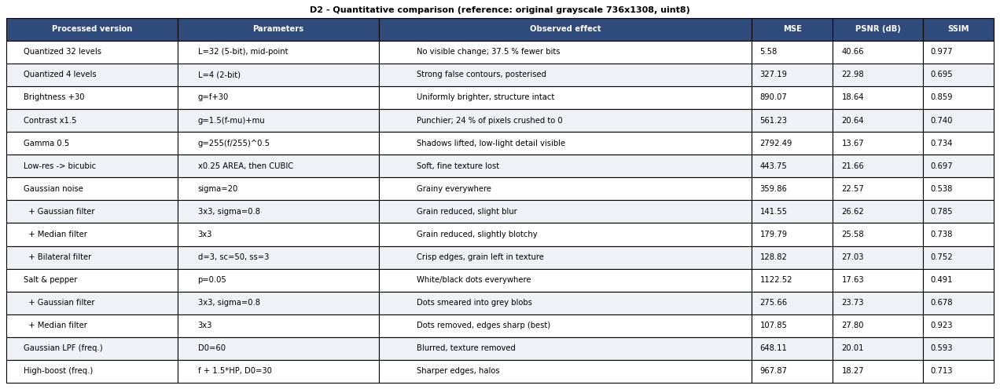

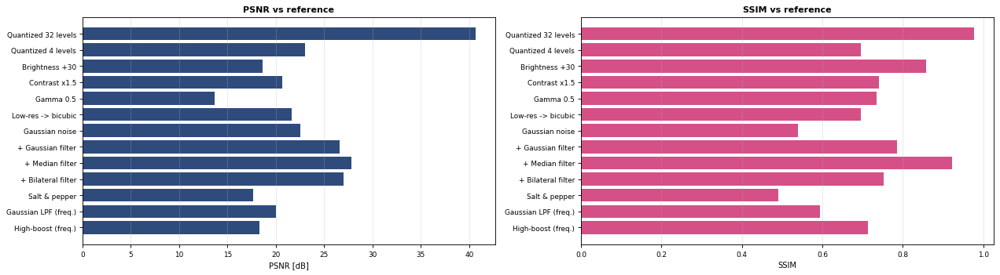

In [ ]:
gn, spn = noisy['Gaussian noise'], noisy['Salt & pepper']
table = [
    # (version, parameters, observed effect, image)
    ("Quantized 32 levels", "L=32 (5-bit), mid-point", "No visible change; 37.5 % fewer bits", quantized[32]),
    ("Quantized 4 levels", "L=4 (2-bit)", "Strong false contours, posterised", quantized[4]),
    ("Brightness +30", "g=f+30", "Uniformly brighter, structure intact", bc_results[('Brightness', 'beta=+30')]),
    ("Contrast x1.5", "g=1.5(f-mu)+mu", "Punchier; 24 % of pixels crushed to 0", bc_results[('Contrast', 'alpha=1.5')]),
    ("Gamma 0.5", "g=255(f/255)^0.5", "Shadows lifted, low-light detail visible", bc_results[('Gamma', 'gamma=0.5')]),
    ("Low-res -> bicubic", f"x{P['lowres_factor']} AREA, then CUBIC", "Soft, fine texture lost", restored_lr['Bicubic']),
    ("Gaussian noise", f"sigma={P['gauss_noise_sigma']}", "Grainy everywhere", gn),
    ("  + Gaussian filter", f"{k}x{k}, sigma={gs}", "Grain reduced, slight blur", filtered[('Gaussian noise', 'Gaussian')]),
    ("  + Median filter", f"{k}x{k}", "Grain reduced, slightly blotchy", filtered[('Gaussian noise', 'Median')]),
    ("  + Bilateral filter", f"d={k}, sc=50, ss={k}", "Crisp edges, grain left in texture", filtered[('Gaussian noise', 'Bilateral')]),
    ("Salt & pepper", f"p={P['sp_density']}", "White/black dots everywhere", spn),
    ("  + Gaussian filter", f"{k}x{k}, sigma={gs}", "Dots smeared into grey blobs", filtered[('Salt & pepper', 'Gaussian')]),
    ("  + Median filter", f"{k}x{k}", "Dots removed, edges sharp (best)", filtered[('Salt & pepper', 'Median')]),
    ("Gaussian LPF (freq.)", f"D0={D0l}", "Blurred, texture removed", lp_u8),
    ("High-boost (freq.)", f"f + {kb}*HP, D0={D0h}", "Sharper edges, halos", highboost),
]
results = []
for name, par, eff, im in table:
    results.append((name, par, eff, mse(REF, im), psnr(REF, im), ssim(REF, im)))

hdr = f"{'Processed version':22s} | {'Parameters':26s} | {'Observed effect':40s} | {'MSE':>8} | {'PSNR dB':>7} | {'SSIM':>5}"
print(hdr); print('-' * len(hdr))
for n, p_, e, m, ps, ss in results:
    print(f"{n:22s} | {p_:26s} | {e:40s} | {m:8.2f} | {ps:7.2f} | {ss:5.3f}")

# Rendered table figure
fig, ax = plt.subplots(figsize=(16, 0.36 * len(results) + 0.9)); ax.axis('off')
cell = [[n, p_, e, f"{m:.2f}", f"{ps:.2f}", f"{ss:.3f}"] for n, p_, e, m, ps, ss in results]
tb = ax.table(cellText=cell, colLabels=['Processed version', 'Parameters', 'Observed effect', 'MSE', 'PSNR (dB)', 'SSIM'],
              colWidths=[.17, .2, .37, .08, .09, .07], cellLoc='left', bbox=[0, 0, 1, 1])
tb.auto_set_font_size(False); tb.set_fontsize(9)
for (r_, c_), cobj in tb.get_celld().items():
    if r_ == 0:
        cobj.set_facecolor('#2f4b7c'); cobj.get_text().set_color('white'); cobj.get_text().set_weight('bold')
    elif r_ % 2 == 0:
        cobj.set_facecolor('#eef1f6')
ax.set_title(f"D2 - Quantitative comparison (reference: original grayscale {W}x{H}, uint8)", fontweight='bold')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
names = [x[0].strip() for x in results]
ps = [min(x[4], 60) for x in results]; ss = [x[5] for x in results]
ax[0].barh(names, ps, color='#2f4b7c'); ax[0].invert_yaxis(); ax[0].set_xlabel('PSNR [dB]'); ax[0].set_title('PSNR vs reference')
ax[1].barh(names, ss, color='#d45087'); ax[1].invert_yaxis(); ax[1].set_xlabel('SSIM'); ax[1].set_title('SSIM vs reference')
for a in ax: a.grid(axis='x', alpha=.3)
plt.tight_layout(); plt.show()

### A case where a numerically better result does **not** look better
Two processed versions are compared: **(A)** the image with Gaussian noise σ = 20 and **(B)** the image brightened by β = +30.

(A) Gaussian noise sigma=20 : MSE   359.9 | PSNR 22.57 dB | SSIM 0.538
(B) Brightness +30          : MSE   890.1 | PSNR 18.64 dB | SSIM 0.859
-> by MSE/PSNR, (A) is 'better'.


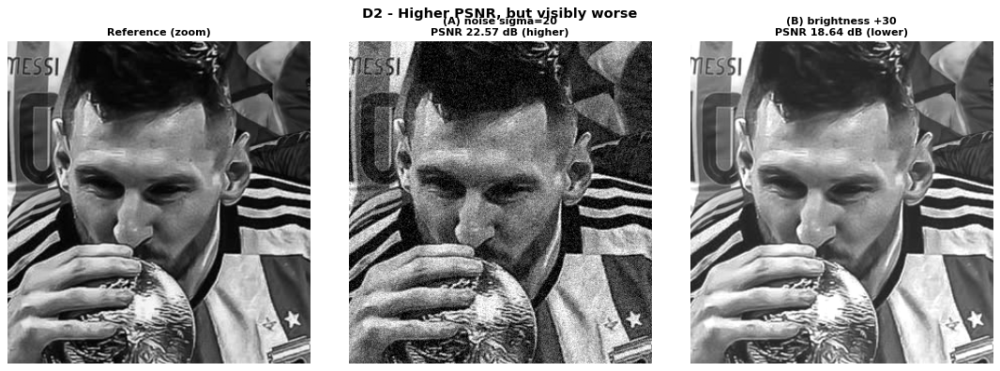

In [ ]:
A_img = gn
B_img = bc_results[('Brightness', 'beta=+30')]
print(f"(A) Gaussian noise sigma=20 : MSE {mse(REF, A_img):7.1f} | PSNR {psnr(REF, A_img):.2f} dB | SSIM {ssim(REF, A_img):.3f}")
print(f"(B) Brightness +30          : MSE {mse(REF, B_img):7.1f} | PSNR {psnr(REF, B_img):.2f} dB | SSIM {ssim(REF, B_img):.3f}")
print("-> by MSE/PSNR, (A) is 'better'.")
zz = (slice(300, 620), slice(240, 540))
show_grid([REF[zz], A_img[zz], B_img[zz]],
          ["Reference (zoom)", f"(A) noise sigma=20\nPSNR {psnr(REF, A_img):.2f} dB (higher)",
           f"(B) brightness +30\nPSNR {psnr(REF, B_img):.2f} dB (lower)"],
          cols=3, panel=(4.6, 5.0), suptitle="D2 - Higher PSNR, but visibly worse")

**Explanation.** Image (A) has the **higher PSNR**, yet it is clearly the worse image: grain covers every surface and fine structure (hair, tattoos, the trophy's engraving) is masked. Image (B) is merely a little brighter — every edge, texture and object boundary is perfectly intact and most viewers would not even call it degraded.

The reason is that MSE treats every pixel error **independently and equally**, regardless of its structure:
* a uniform offset of +30 gives an error of ≈ 30 at almost *every* pixel → MSE ≈ 30² ≈ 900 (slightly less because of clipping at 255);
* zero-mean noise with σ = 20 gives MSE ≈ σ² = 400 (360 measured, slightly less because of clipping at 0/255), even though it destroys local structure.

The human visual system, however, adapts to global luminance changes and is very sensitive to **structural** distortions. SSIM, which separates luminance, contrast and structure, agrees with the eye here: **0.859 for B vs 0.538 for A**. A second example appears in Part E: the final unsharp-masking step *lowers* PSNR slightly while making edges look crisper. **Therefore PSNR/MSE should be complemented by a structural metric (SSIM) and visual inspection** when tuning the preprocessing module.

---
# Part E — Integrated preprocessing module for low-light, low-resolution input
The individual operations are now chained into the module the question describes. To evaluate it objectively, a **low-quality capture is simulated** from the reference, so the ideal output (the reference) is known:

$$f_{\text{low}} = \downarrow_{0.5}\!\Big[\,255\cdot 0.35\,(R/255)^{1.6}\Big] + n,\quad n\sim\mathcal N(0,4^2)$$
(under-exposure + shadow compression → half resolution → sensor noise).

**Restoration chain** (order justified by Parts A–C):
1. **Denoise first, at native resolution** — bilateral filter (edge-preserving, B2); denoising before brightening prevents gamma/contrast from amplifying noise.
2. **Up-sample ×2 with bicubic** (best interpolator in A3).
3. **Tone restoration** — percentile contrast stretch (B1, robust to outliers) then an **automatic gamma** $\gamma=\ln(0.40)/\ln(\bar s)$ that brings the mean to a 40 % exposure target (no knowledge of the true degradation is used).
4. **Unsharp masking** $g = t + k\,(t - G_{\sigma}*t)$ — a spatial high-boost (C2) to restore edge contrast.

Edge preservation is measured by the correlation between the Sobel-magnitude maps of output and reference (B3).

Simulated capture: 368x654, mean 17.4 (reference mean 76.9)

Stage                             MSE  PSNR dB   SSIM Edge corr
0 Received (nearest-upscaled)   5513.1    10.72  0.215     0.794
1 Bilateral denoise            5635.3    10.62  0.191     0.800
2 Bicubic upscale              5614.7    10.64  0.192     0.828
3 Stretch + gamma 0.60          408.4    22.02  0.677     0.815
4 Unsharp k=0.5                 417.9    21.92  0.671     0.829


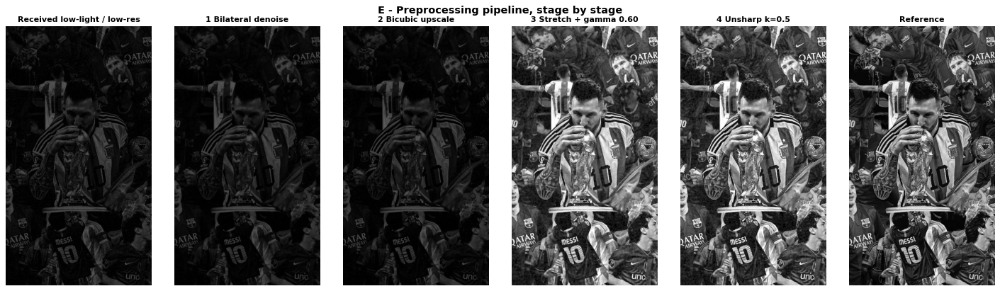

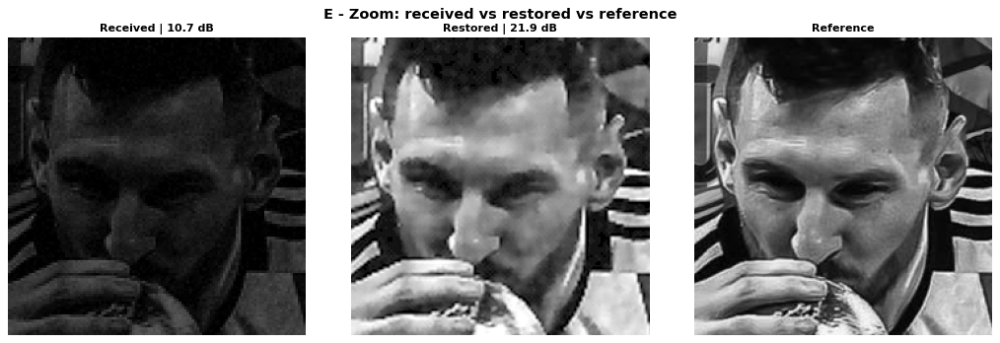

In [ ]:
def simulate_low_quality(ref, seed=SEED):
    x = ref.astype(np.float64) / 255.0
    dark = P['sim_exposure'] * x ** P['sim_gamma']
    small = cv2.resize(dark, None, fx=P['sim_downscale'], fy=P['sim_downscale'], interpolation=cv2.INTER_AREA)
    rng = np.random.default_rng(seed)
    return to_u8(255 * small + rng.normal(0, P['sim_noise_sigma'], small.shape))

def edge_corr(ref, img):
    e = lambda z: np.hypot(cv2.Sobel(z.astype(float), cv2.CV_64F, 1, 0), cv2.Sobel(z.astype(float), cv2.CV_64F, 0, 1)).ravel()
    return float(np.corrcoef(e(ref), e(img))[0, 1])

def restore(low, out_size, target_mean=None, k_us=None, s_us=None):
    target_mean = P['target_mean'] if target_mean is None else target_mean
    k_us = P['unsharp_k'] if k_us is None else k_us
    s_us = P['unsharp_sigma'] if s_us is None else s_us
    stages = {}
    den = cv2.bilateralFilter(low, 5, 12, 3);                        stages['1 Bilateral denoise'] = den
    up = cv2.resize(den, out_size, interpolation=cv2.INTER_CUBIC);    stages['2 Bicubic upscale'] = up
    upf = up.astype(np.float64)
    lo, hi = np.percentile(upf, [0.5, 99.5])
    s_ = np.clip((upf - lo) / (hi - lo), 0, 1)
    gam = np.log(target_mean) / np.log(s_.mean())
    tone = 255 * s_ ** gam;                                         stages[f'3 Stretch + gamma {gam:.2f}'] = to_u8(tone)
    blur = cv2.GaussianBlur(tone, (0, 0), s_us)
    sharp = to_u8(tone + k_us * (tone - blur));                     stages[f'4 Unsharp k={k_us}'] = sharp
    return sharp, stages

low = simulate_low_quality(REF)
received = cv2.resize(low, (W, H), interpolation=cv2.INTER_NEAREST)   # as displayed by a naive system
restored, stages = restore(low, (W, H))
print(f"Simulated capture: {low.shape[1]}x{low.shape[0]}, mean {low.mean():.1f} (reference mean {REF.mean():.1f})")

print(f"\n{'Stage':28s} {'MSE':>8} {'PSNR dB':>8} {'SSIM':>6} {'Edge corr':>9}")
evals = [('0 Received (nearest-upscaled)', received)]
for n, im in stages.items():
    evals.append((n, im if im.shape == REF.shape else cv2.resize(im, (W, H), interpolation=cv2.INTER_NEAREST)))
for n, im in evals:
    print(f"{n:28s} {mse(REF, im):8.1f} {psnr(REF, im):8.2f} {ssim(REF, im):6.3f} {edge_corr(REF, im):9.3f}")

show_grid([received] + [e[1] for e in evals[1:]] + [REF],
          ["Received low-light / low-res"] + [e[0] for e in evals[1:]] + ["Reference"],
          cols=6, panel=(3.0, 5.2), suptitle="E - Preprocessing pipeline, stage by stage")
zz = (slice(330, 560), slice(270, 500))
show_grid([received[zz], restored[zz], REF[zz]],
          [f"Received | {psnr(REF, received):.1f} dB", f"Restored | {psnr(REF, restored):.1f} dB", "Reference"],
          cols=3, panel=(4.4, 4.4), suptitle="E - Zoom: received vs restored vs reference")

**Result.** The pipeline turns an almost unusable dark, noisy, half-resolution frame (mean grey level 17 vs 77) into an image close to the reference: **PSNR 10.7 → 21.9 dB** and **SSIM 0.215 → 0.671**, while the edge-map correlation rises from 0.794 to 0.829 — boundaries are preserved and slightly strengthened, never degraded.

The stage table shows *what each step contributes*:
* **Denoise and bicubic up-sample** barely change PSNR/SSIM while the image is still dark (the error is dominated by the 60-grey-level brightness gap), but they raise the edge correlation (0.794 → 0.828): noise is removed and blocky nearest-neighbour edges become smooth contours.
* **Stretch + automatic gamma (γ = 0.60)** produces the big jump (+11.4 dB, SSIM ×3.5) by restoring the tonal range without clipping. Edge correlation dips slightly (0.815) because gamma also amplifies residual noise in the shadows.
* **Unsharp masking** restores edge contrast (edge correlation 0.829, the highest) at the cost of 0.1 dB PSNR — a second instance of "numerically better ≠ visually better" (D2).

Some loss is unavoidable: detail destroyed by down-sampling and shadows crushed by the under-exposure cannot be recovered by any of these operations.

---
# Bonus — Interactive GUI (ipywidgets)
A graphical front-end for the whole module. Every operation from Parts A–C is a control; the output, its histogram and its log-spectrum update live, together with MSE / PSNR / SSIM against the reference. **Run the cell in Colab** (widgets need a live kernel; a saved notebook shows no GUI until executed).

* **Input:** original image or the simulated low-quality capture (Part E).
* **Processing order:** geometry → brightness/contrast/gamma → quantization → noise → spatial filter → frequency filter → edge detector (documented in the GUI).
* **Presets** reproduce typical experiments in one click; **Reset** restores defaults; **Save** writes `gui_output.png` (and downloads it on Colab).
* Metrics are computed on grayscale. With geometric transforms enabled they mostly measure misalignment (see D1).

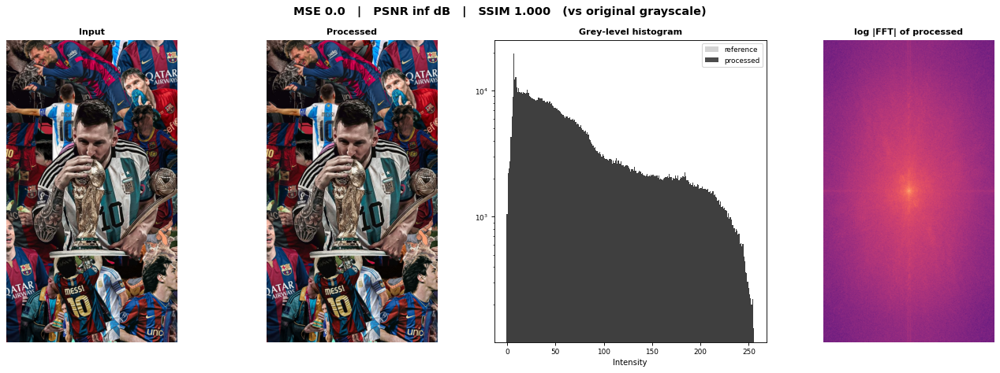

In [ ]:
try:
    import ipywidgets as w
    from IPython.display import display
    GUI_OK = True
except ImportError:
    GUI_OK = False
    print("ipywidgets not installed - run `pip install ipywidgets` (pre-installed on Colab).")

received_color = None
def gui_input(src, colour):
    if src == 'Simulated low-quality (Part E)':
        g = received if 'received' in globals() else gray
        return cv2.cvtColor(g, cv2.COLOR_GRAY2RGB) if colour else g
    return img_rgb.copy() if colour else gray.copy()

def per_channel(fn, img):
    if img.ndim == 2: return fn(img)
    return np.dstack([fn(img[..., c]) for c in range(img.shape[2])])

def gui_process(src, colour, angle, scale, tx_, ty_, interp, border, beta, alpha, gamma, bits,
                noise, nlevel, filt, ksz, freq, D0, edge):
    img = gui_input(src, colour)
    h, w_ = img.shape[:2]
    # 1. geometry
    if angle != 0 or scale != 1 or tx_ != 0 or ty_ != 0:
        Mg = cv2.getRotationMatrix2D((w_ / 2, h / 2), angle, scale); Mg[0, 2] += tx_; Mg[1, 2] += ty_
        img = cv2.warpAffine(img, Mg, (w_, h), flags=interp, borderMode=border)
    # 2. intensity
    pivot = float(img.mean())
    img = gamma_correct(adjust_brightness(adjust_contrast(img, alpha, pivot), beta), gamma)
    # 3. quantization
    if bits < 8: img = quantize(img, 2 ** bits)
    # 4. noise
    if noise == 'Gaussian': img = add_gaussian_noise(img, nlevel)
    elif noise == 'Salt & pepper': img = add_salt_pepper(img, nlevel / 100.0)
    # 5. spatial filter
    if filt == 'Mean':       img = cv2.blur(img, (ksz, ksz))
    elif filt == 'Gaussian': img = cv2.GaussianBlur(img, (ksz, ksz), 0)
    elif filt == 'Median':   img = cv2.medianBlur(img, ksz)
    elif filt == 'Bilateral':img = cv2.bilateralFilter(img, ksz, 50, ksz)
    # 6. frequency filter
    if freq != 'None':
        shp = img.shape[:2]
        if freq == 'Gaussian LPF':  img = per_channel(lambda c: to_u8(freq_filter(c, gaussian_lp(shp, D0))[0]), img)
        if freq == 'Ideal LPF':     img = per_channel(lambda c: to_u8(freq_filter(c, ideal_lp(shp, D0))[0]), img)
        if freq == 'Gaussian HPF':  img = per_channel(lambda c: norm_u8(np.clip(freq_filter(c, gaussian_hp(shp, D0))[0], -60, 60)), img)
        if freq == 'High-boost':    img = per_channel(lambda c: to_u8(c + P['highboost_k'] * freq_filter(c, gaussian_hp(shp, D0))[0]), img)
    # 7. edges
    if edge != 'None':
        gg = (cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if img.ndim == 3 else img).astype(np.float64)
        if edge == 'Sobel magnitude':
            e = np.hypot(cv2.Sobel(gg, cv2.CV_64F, 1, 0), cv2.Sobel(gg, cv2.CV_64F, 0, 1))
        elif edge == 'Laplacian |.|':
            e = np.abs(cv2.Laplacian(gg, cv2.CV_64F))
        else:
            e = np.abs(cv2.Laplacian(cv2.GaussianBlur(gg, (0, 0), 2), cv2.CV_64F))
        img = to_u8(255 * np.clip(e / np.percentile(e, 99.5), 0, 1))
    return img

if GUI_OK:
    sl = dict(continuous_update=False, style={'description_width': '110px'}, layout=w.Layout(width='360px'))
    W_ = {
        'src':    w.Dropdown(options=['Original', 'Simulated low-quality (Part E)'], value='Original', description='Input', **{k_: v_ for k_, v_ in sl.items() if k_ != 'continuous_update'}),
        'colour': w.Checkbox(value=True, description='Colour processing'),
        'angle':  w.IntSlider(value=0, min=-180, max=180, step=5, description='Rotation (deg)', **sl),
        'scale':  w.FloatSlider(value=1.0, min=0.25, max=3.0, step=0.05, description='Scale', **sl),
        'tx_':    w.IntSlider(value=0, min=-300, max=300, step=10, description='Translate x', **sl),
        'ty_':    w.IntSlider(value=0, min=-300, max=300, step=10, description='Translate y', **sl),
        'interp': w.Dropdown(options=[('Nearest', cv2.INTER_NEAREST), ('Bilinear', cv2.INTER_LINEAR), ('Bicubic', cv2.INTER_CUBIC), ('Lanczos-4', cv2.INTER_LANCZOS4)], value=cv2.INTER_LINEAR, description='Interpolation', style=sl['style'], layout=sl['layout']),
        'border': w.Dropdown(options=[('Constant (black)', cv2.BORDER_CONSTANT), ('Replicate', cv2.BORDER_REPLICATE), ('Reflect 101', cv2.BORDER_REFLECT_101), ('Wrap', cv2.BORDER_WRAP)], value=cv2.BORDER_CONSTANT, description='Border', style=sl['style'], layout=sl['layout']),
        'beta':   w.IntSlider(value=0, min=-150, max=150, step=5, description='Brightness beta', **sl),
        'alpha':  w.FloatSlider(value=1.0, min=0.1, max=3.0, step=0.05, description='Contrast alpha', **sl),
        'gamma':  w.FloatSlider(value=1.0, min=0.2, max=3.0, step=0.05, description='Gamma', **sl),
        'bits':   w.IntSlider(value=8, min=1, max=8, step=1, description='Quantization bits', **sl),
        'noise':  w.Dropdown(options=['None', 'Gaussian', 'Salt & pepper'], value='None', description='Noise', style=sl['style'], layout=sl['layout']),
        'nlevel': w.FloatSlider(value=20, min=0, max=60, step=1, description='sigma / density %', **sl),
        'filt':   w.Dropdown(options=['None', 'Mean', 'Gaussian', 'Median', 'Bilateral'], value='None', description='Spatial filter', style=sl['style'], layout=sl['layout']),
        'ksz':    w.IntSlider(value=5, min=3, max=15, step=2, description='Kernel size', **sl),
        'freq':   w.Dropdown(options=['None', 'Gaussian LPF', 'Ideal LPF', 'Gaussian HPF', 'High-boost'], value='None', description='Freq. filter', style=sl['style'], layout=sl['layout']),
        'D0':     w.IntSlider(value=30, min=2, max=200, step=1, description='Cut-off D0', **sl),
        'edge':   w.Dropdown(options=['None', 'Sobel magnitude', 'Laplacian |.|', 'LoG |.|'], value='None', description='Edge detector', style=sl['style'], layout=sl['layout']),
    }
    DEFAULTS = {k_: v_.value for k_, v_ in W_.items()}
    PRESETS = {
        'Low-light enhancement': dict(src='Simulated low-quality (Part E)', colour=False, filt='Bilateral', ksz=5, gamma=0.55, alpha=1.3, freq='High-boost', D0=60),
        'Salt & pepper -> median': dict(noise='Salt & pepper', nlevel=5, filt='Median', ksz=5),
        'Gaussian noise -> Gaussian': dict(noise='Gaussian', nlevel=20, filt='Gaussian', ksz=5),
        'False contouring (3-bit)': dict(bits=3),
        'Rotation & border handling': dict(angle=30, border=cv2.BORDER_REFLECT_101),
        'Frequency LPF ringing': dict(freq='Ideal LPF', D0=20),
        'Edge map (Sobel)': dict(edge='Sobel magnitude'),
    }
    preset = w.Dropdown(options=['(choose preset)'] + list(PRESETS), description='Preset', style=sl['style'], layout=sl['layout'])
    btn_reset = w.Button(description='Reset', icon='undo', button_style='warning')
    btn_save = w.Button(description='Save output', icon='save', button_style='success')
    status = w.HTML()
    state = {'last': None}

    def render(**kw):
        out = gui_process(**kw)
        state['last'] = out
        ref_in = gui_input('Original', False)
        g_out = cv2.cvtColor(out, cv2.COLOR_RGB2GRAY) if out.ndim == 3 else out
        fig, ax = plt.subplots(1, 4, figsize=(17, 6), gridspec_kw={'width_ratios': [1, 1, 1.15, 1]})
        src = gui_input(kw['src'], kw['colour'])
        ax[0].imshow(src, cmap=None if src.ndim == 3 else 'gray', vmin=0, vmax=255); ax[0].set_title('Input'); ax[0].axis('off')
        ax[1].imshow(out, cmap=None if out.ndim == 3 else 'gray', vmin=0, vmax=255); ax[1].set_title('Processed'); ax[1].axis('off')
        ax[2].bar(range(256), np.bincount(ref_in.ravel(), minlength=256), color='lightgray', width=1, label='reference')
        ax[2].bar(range(256), np.bincount(g_out.ravel(), minlength=256), color='k', width=1, alpha=.7, label='processed')
        ax[2].set_yscale('log'); ax[2].set_title('Grey-level histogram'); ax[2].set_xlabel('Intensity'); ax[2].legend(fontsize=8)
        ax[3].imshow(np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g_out.astype(float))))), cmap='magma'); ax[3].set_title('log |FFT| of processed'); ax[3].axis('off')
        fig.suptitle(f"MSE {mse(ref_in, g_out):.1f}   |   PSNR {psnr(ref_in, g_out):.2f} dB   |   SSIM {ssim(ref_in, g_out):.3f}   (vs original grayscale)")
        plt.tight_layout(); plt.show()

    out_w = w.Output()
    state['hold'] = False

    def refresh(*_):
        # Re-render once with the current widget values (skipped while a preset is being applied).
        if state['hold']:
            return
        with out_w:
            out_w.clear_output(wait=True)
            render(**{k_: v_.value for k_, v_ in W_.items()})
    for v_ in W_.values():
        v_.observe(refresh, names='value')

    def set_values(values):
        state['hold'] = True
        try:
            for k_, v_ in values.items(): W_[k_].value = v_
        finally:
            state['hold'] = False
        refresh()

    def apply_preset(change):
        if change['new'] in PRESETS:
            set_values({**DEFAULTS, **PRESETS[change['new']]})
            status.value = f"<b>Preset applied:</b> {change['new']}"
    preset.observe(apply_preset, names='value')

    def do_reset(_):
        set_values(DEFAULTS)
        preset.value = '(choose preset)'; status.value = 'Reset to defaults.'
    btn_reset.on_click(do_reset)

    def do_save(_):
        if state['last'] is None: return
        im = state['last']
        cv2.imwrite('gui_output.png', cv2.cvtColor(im, cv2.COLOR_RGB2BGR) if im.ndim == 3 else im)
        status.value = "Saved <code>gui_output.png</code>."
        if IN_COLAB:
            from google.colab import files; files.download('gui_output.png')
    btn_save.on_click(do_save)

    col = lambda *ks: w.VBox([W_[k_] for k_ in ks])
    tabs = w.Tab(children=[
        w.VBox([W_['src'], W_['colour']]),
        col('angle', 'scale', 'tx_', 'ty_', 'interp', 'border'),
        col('beta', 'alpha', 'gamma', 'bits'),
        col('noise', 'nlevel', 'filt', 'ksz'),
        col('freq', 'D0'),
        col('edge'),
    ])
    for i, t in enumerate(['Input', 'A: Geometry', 'B1: Intensity / quant.', 'B2: Noise & filter', 'C: Frequency', 'B3: Edges']):
        tabs.set_title(i, t)
    header = w.HTML("<h3 style='margin:4px 0'>Image Restoration &amp; Enhancement - interactive preprocessing module</h3>"
                    "<i>Order: geometry → intensity → quantization → noise → spatial filter → frequency filter → edges</i>")
    display(w.VBox([header, w.HBox([preset, btn_reset, btn_save]), status, tabs, out_w]))
    refresh()

---
# F. Conclusions
1. **Representation (A1):** the input is a 736 × 1308 `uint8` sRGB PNG (RGBA with an all-opaque alpha, loaded as 3 channels); BT.601 grayscale reduces it to one luminance channel (3× less data) and keeps the edge/shape information the module needs, at the irreversible cost of colour.
2. **Quantization (A2):** 5-bit is visually lossless (40.7 dB, SSIM 0.98); ≤ 3 bits creates false contours that would be mistaken for edges. Error follows $\Delta^2/12$ (≈ 6 dB per bit).
3. **Geometry (A3):** affine matrices with inverse mapping; bicubic for up-sampling, area averaging for down-sampling, reflect borders before filtering. Interpolation cannot recreate detail lost to low resolution.
4. **Intensity (B1):** brightness offsets and contrast gains clip a dark image quickly (β = −50 crushes 45 % of pixels, α = 1.5 crushes 24 %); **gamma < 1** lifts shadows with no extra clipping and is the right tool for low-light frames.
5. **Denoising (B2):** median for impulse noise (27.8 dB, SSIM 0.92), Gaussian/bilateral for sensor noise (≈ 27 dB); bilateral best preserves boundaries. k = 3 is optimal for this finely textured image.
6. **Edges (B3):** Sobel (1st order) gives robust, oriented, thick edges; Laplacian (2nd order) gives precise zero-crossings but ≈ 5× the relative noise → use LoG.
7. **Frequency domain (C):** the shifted log-spectrum shows energy concentrated at low frequencies; Gaussian LPF/HPF avoid the ringing of ideal filters; the frequency and spatial Gaussian give identical interior results, with the FFT winning only for large kernels.
8. **Evaluation (D):** reference = original grayscale. PSNR/MSE are useful but blind to structure — a +30 brightness shift scores worse than heavy noise; SSIM and visual inspection are needed.
9. **Integrated module (E):** denoise → bicubic up-sample → stretch + auto-gamma → unsharp mask raises PSNR from 10.7 to 21.9 dB and SSIM from 0.22 to 0.67 on a simulated low-light, low-resolution capture, while edge correlation improves (0.79 → 0.83).

### Viva quick-reference: "change a parameter, predict the effect"
| If the examiner changes… | Predicted effect (and where to verify) |
|---|---|
| `quant_levels` → fewer levels | MSE ×4 per bit removed (≈ −6 dB), more false contours, entropy → log₂L (A2 table) |
| `rot_angle` → 45° | larger black corners with CONSTANT border; expanded canvas grows to ≈ 1445 × 1445 (A3) |
| `brightness_betas` → ±100 | heavy clipping, PSNR falls ≈ as $20\log_{10}(255/\beta)$ until clipping dominates (B1 table) |
| `gauss_noise_sigma` → 40 | noisy PSNR ≈ $20\log_{10}(255/40)$ ≈ 16 dB; larger kernels become optimal (B2 sweep) |
| `sp_density` → 0.2 | 3 × 3 median starts leaving dots: P(≥ 5 of 9 pixels corrupted) ≈ 2 %; switch to 5 × 5 (B2) |
| `filter_ksize` → 9 | more noise removed but much more blur; PSNR drops (e.g. Gaussian on Gaussian noise 26.5 → 22.0 dB, B2 sweep) |
| `D0_lp` → 20 | much stronger blur, wider ringing for the ideal filter, lower PSNR and less energy kept (C2 sweep) |
| `D0_hp` → 80 | HPF keeps only the finest texture/noise; high-boost sharpens less (C2) |
| `equiv_sigma` → 16 | spatial cost grows (97 × 97 kernel), FFT time unchanged (C3 timing) |

All values are in the dictionary `P` (Section 0) — edit, then **Runtime ▸ Run all**.